# Mortgage Renewal Pricing Optimization

## Notebook Overview

This notebook presents a complete, end-to-end workflow for simulating, modeling, and optimizing mortgage renewal offers. The objective is to demonstrate how customer-level data, behavioral assumptions, and predictive modeling can be integrated to produce profitable and analytically defensible mortgage pricing decisions.

The workflow is organized into five major stages:

**Synthetic Data Generation**

A realistic dataset of mortgage customers is constructed to mirror the structure of proprietary banking data. Key features include credit attributes (FICO score, debt-to-income ratio), financial characteristics (income, loan amount, mortgage term), tenure, and behavioral segments. Each customer is assigned a single behavioral segment that is conditioned on their profile, and historical offers vary around a term-specific target spread so that the data contains genuine pricing variation to learn from.

**Exploratory Data Analysis (EDA) and Assumption Validation**

The dataset is analyzed to understand distributions, segment composition, and feature relationships, confirming that each generation assumption behaves as intended.

**Acceptance Probability Modeling**

A behavioral acceptance function defines the "true" probability that a customer accepts an offer, with segment-specific price elasticity. Logistic Regression, Random Forest, and XGBoost models are trained on simulated outcomes and evaluated on discrimination, calibration, and, most importantly for pricing, how faithfully they reproduce the customer's response to rate changes.

**Mortgage Rate Optimization**

The selected model drives a customer-level optimizer that searches a grid of rate adjustments and selects the one that maximizes expected annual margin, subject to business rules: a minimum spread floor and loyalty protection that caps increases for long-tenure and loyal customers.

**Optimization Evaluation and Insights**

Because the data is synthetic, the true acceptance function is known. Recommended prices are therefore scored against ground truth and compared with an oracle optimizer that prices using the true function, quantifying how much of the achievable value the model actually captures.

---

## Imports and Setup

*Loading libraries and defining global reproducibility*

In [1]:
# standard
import numpy as np
import pandas as pd
from pathlib import Path
import joblib

# math
from scipy.special import expit

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# sci-kit learn
from sklearn.model_selection import train_test_split, GridSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

# xgboost
from xgboost import XGBClassifier

# global reproducibility: a single generator is passed to every simulation step
SEED = 42
rng = np.random.default_rng(SEED)

Create Output Directories

In [2]:
# project root = current notebook working directory
PROJECT_ROOT = Path.cwd()

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = OUTPUTS_DIR / "models"
DATA_DIR = OUTPUTS_DIR / "data"
METRICS_DIR = OUTPUTS_DIR / "metrics"
REPRO_DIR = OUTPUTS_DIR / "reproducibility"

# create folders
for folder in [FIGURES_DIR, MODELS_DIR, DATA_DIR, METRICS_DIR, REPRO_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Assets directory: {OUTPUTS_DIR.relative_to(PROJECT_ROOT)}")

Assets directory: outputs


Save Figure Helper Function

In [3]:
def save_figure(filename, dpi=300):
    filepath = FIGURES_DIR / filename

    plt.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight"
    )

    print(f"Saved: {filepath.relative_to(PROJECT_ROOT)}")

In [4]:
# setting plotting style
sns.set_theme(style="whitegrid")

SEGMENTS = ["shopper", "loyal", "risk_averse", "premium", "subprime"]
SEGMENT_PALETTE = dict(zip(SEGMENTS, sns.color_palette("Set2", n_colors=len(SEGMENTS))))

---

## Synthetic Data Generation

In this section, I construct a synthetic customer dataset designed to capture key demographic, financial, and behavioral attributes relevant to mortgage-renewal decisions. This dataset forms the foundation for modeling customer acceptance probabilities and optimizing mortgage offers in a controlled, reproducible environment.

**Objectives**

* Create a representative customer base with features such as FICO score, income, debt-to-income ratio (DTI), tenure, mortgage term, and loan amount.
* Assign each customer a stable behavioral segment that is consistent with their financial profile.
* Assign term-based funding rates and simulate historical offers that vary around a target spread, giving the models real pricing variation to learn from.
* Generate a 36-month panel of offers suitable for predictive modeling and profit optimization.

### FICO Score Simulation

FICO scores for synthetic customers are sampled using recent U.S. population distributions as a baseline (Arkali 2024). Each score is randomly drawn within predefined ranges, with probabilities proportional to the share of the population in that range.

In [5]:
def generate_fico_scores(n_customers, fico_dist, rng):
    """
    Generate synthetic FICO scores for customers based on a target population distribution.

    Args:
        n_customers (int): Number of customers to generate
        fico_dist (dict): Keys are FICO ranges (e.g., "300-499"), values are population shares
        rng (np.random.Generator): Random number generator

    Returns:
        np.array: Array of generated FICO scores for each customer
    """
    fico_ranges = np.array([tuple(map(int, k.split("-"))) for k in fico_dist.keys()])
    sampled_ranges = rng.choice(len(fico_ranges), size=n_customers, p=list(fico_dist.values()))
    low, high = fico_ranges[sampled_ranges, 0], fico_ranges[sampled_ranges, 1]
    return rng.integers(low, high + 1)

### Income Distribution Modeling

Income is modeled using a log-normal distribution calibrated to the U.S. median household income, with the spread derived from the 10th and 90th percentiles (U.S. Census Bureau 2025). Incomes below $30k are clipped, reflecting a minimum income to qualify for a mortgage.

In [6]:
def generate_income(n_customers, rng, median_income=83730, p10_income=33000, p90_income=160000):
    """
    Generate synthetic income values using a log-normal distribution.

    Args:
        n_customers (int): Number of customers to generate
        rng (np.random.Generator): Random number generator
        median_income (float): Median income for log-normal distribution
        p10_income (float): 10th percentile income (for sigma scaling)
        p90_income (float): 90th percentile income (for sigma scaling)

    Returns:
        np.array: Array of generated income values, clipped at minimum 30k
    """
    mu = np.log(median_income)
    sigma = (np.log(p90_income) - np.log(p10_income)) / 2.56
    income = rng.lognormal(mean=mu, sigma=sigma, size=n_customers)
    return np.clip(income, 30000, None)

### Debt-to-Income (DTI) Computation

DTI is calculated using an inverse-U function of income: middle-income customers tend to carry higher relative debt, while lower- and higher-income borrowers maintain lower DTI ratios.

In [7]:
def calculate_dti(income, median_income=83730, min_dti=0.15, max_dti=0.45, scale=55000):
    """
    Map income to a debt-to-income ratio using an inverse-U function.

    Args:
        income (array-like): Array of customer incomes
        median_income (float): Income at which DTI peaks
        min_dti (float): Minimum DTI allowed
        max_dti (float): Maximum DTI allowed
        scale (float): Scaling factor controlling curvature of the inverse-U

    Returns:
        np.array: Array of DTI values between min_dti and max_dti
    """
    dti_raw = 1 - ((np.asarray(income) - median_income) / scale) ** 2
    dti_raw = np.clip(dti_raw, 0, 1)
    return min_dti + dti_raw * (max_dti - min_dti)

### Constructing Base Customer Profiles

Customer profiles combine FICO, income, DTI, tenure, and mortgage term into a unified record. Tenure follows an exponential distribution with a mean of 5 years, so most customers are relatively new to the bank with a long tail of long-standing relationships.

In [8]:
def generate_customers(n_customers, fico_dist, rng):
    """
    Generate a synthetic customer dataset by combining key financial
    and demographic attributes into cohesive borrower profiles.

    Parameters
    ----------
    n_customers : int
        Number of synthetic customer records to generate.
    fico_dist : dict
        Population FICO score distribution used to sample credit scores.
    rng : np.random.Generator
        Random number generator.

    Returns
    -------
    pandas.DataFrame
        Simulated customer profiles with FICO, income, DTI, tenure, and term.
    """
    income = generate_income(n_customers, rng)

    customers = pd.DataFrame({
        "customer_id": np.arange(1, n_customers + 1),
        "fico": generate_fico_scores(n_customers, fico_dist, rng),
        "income": income,
        "dti": calculate_dti(income),
        "tenure_yrs": rng.exponential(5, n_customers).clip(0, 30),
        "term": rng.choice([15, 20, 30], n_customers, p=[0.2, 0.3, 0.5]),
    })
    return customers

### Modeling Behavioral Characteristics of Renewal Decisions

Beyond financial characteristics, customer behavior plays a critical role in renewal outcomes. Each customer receives:

* **Rate elasticity:** individual responsiveness to price, centered on 1.0.
* **Market sensitivity:** tendency to compare offers and seek alternatives.
* **Loyalty factor:** rises from 0.5 for a new customer toward 1.0 for long-tenure relationships.
* **Behavioral segment:** assigned once per customer and conditioned on their profile. Long-tenure customers are more likely to be loyal, high-FICO high-income customers are more likely to be premium, and low-FICO customers are more likely to be subprime.
* **Customer effect:** an unobserved, persistent propensity to renew, representing factors a bank cannot measure directly (life events, branch relationship, competing offers).

Rate elasticity, market sensitivity, and the customer effect drive acceptance but are deliberately excluded from the model features, since a bank would not observe them. This keeps the prediction problem realistically imperfect.

*This function adds behavioral traits and a single, profile-conditioned segment to each customer.*

In [9]:
def add_behavioral_attributes(customers, rng):
    """
    Add behavioral characteristics that influence renewal decisions.

    Parameters
    ----------
    customers : pandas.DataFrame
        DataFrame containing baseline customer financial attributes.
    rng : np.random.Generator
        Random number generator.

    Returns
    -------
    pandas.DataFrame
        Updated DataFrame including:
        - rate_elasticity: responsiveness to interest-rate changes
        - market_sensitivity: tendency to compare or seek alternative offers
        - loyalty_factor: increases with tenure, from 0.5 toward 1.0
        - segment: behavioral persona, fixed per customer
        - customer_effect: unobserved persistent renewal propensity
    """
    customers = customers.copy()
    n = len(customers)

    customers["rate_elasticity"] = rng.normal(1.0, 0.25, n).clip(0.4, 1.6)
    customers["market_sensitivity"] = rng.uniform(0.4, 1.0, n)
    customers["loyalty_factor"] = 1 - 0.5 / (1 + customers["tenure_yrs"])

    # segment weights conditioned on the customer profile (order matches SEGMENTS)
    weights = np.column_stack([
        np.full(n, 1.0),                                                        # shopper
        0.4 + 1.6 * (customers["tenure_yrs"] > 7),                              # loyal
        np.full(n, 0.8),                                                        # risk_averse
        0.2 + 1.8 * ((customers["fico"] >= 740) & (customers["income"] >= 100_000)),  # premium
        0.1 + 2.5 * (customers["fico"] < 620),                                  # subprime
    ])
    probs = weights / weights.sum(axis=1, keepdims=True)

    # inverse-CDF sampling: one segment draw per customer
    draws = rng.random(n)[:, None]
    customers["segment"] = np.array(SEGMENTS)[(draws > probs.cumsum(axis=1)).sum(axis=1)]

    customers["customer_effect"] = rng.normal(0, 0.35, n)
    return customers

### Simulating Longitudinal Customer Behavior and Historical Offers

Each customer is expanded into a monthly panel. FICO and income receive small stochastic shocks each month and DTI is recalculated.

Each month the customer also receives an offer. The funding rate depends on term, and the offered spread varies around a term-specific target (150, 175, and 200 bps for 15, 20, and 30-year terms) with a standard deviation of 30 bps. This variation represents historical rate-desk discretion, competitive matching, and pricing tests. It is what allows a model to learn how acceptance responds to price. Without it, rate effects cannot be separated from customer effects.

In [10]:
FUNDING_CURVE = {15: 0.032, 20: 0.034, 30: 0.036}
TARGET_SPREAD_BPS = {15: 150, 20: 175, 30: 200}


def generate_time_series(customers, rng, n_months=36, spread_std_bps=30,
                         min_spread_bps=60, max_spread_bps=320):
    """
    Generate a monthly panel dataset with evolving customer attributes
    and one historical renewal offer per customer-month.

    Parameters
    ----------
    customers : pandas.DataFrame
        Baseline customer dataset containing financial and behavioral attributes.
    rng : np.random.Generator
        Random number generator.
    n_months : int, optional
        Number of months to simulate (default is 36).
    spread_std_bps : float, optional
        Standard deviation of historical offers around the target spread.
    min_spread_bps, max_spread_bps : float, optional
        Bounds on historical offered spreads.

    Returns
    -------
    pandas.DataFrame
        Long-format panel with one row per customer-month, including
        funding_rate, target_spread_bps, spread_bps, offered_rate and month.
    """
    months = pd.date_range(start="2023-01-01", periods=n_months, freq="MS")
    n = len(customers)

    # repeating each customer once per month (month-major order)
    panel = pd.concat([customers] * n_months, ignore_index=True)
    panel["month"] = np.repeat(months, n)

    # monthly drift in credit and income, then recomputing DTI
    panel["fico"] = (panel["fico"] + rng.normal(0, 1, len(panel))).clip(300, 850).astype(int)
    panel["income"] = panel["income"] * (1 + rng.normal(0, 0.005, len(panel)))
    panel["dti"] = calculate_dti(panel["income"])

    # pricing: term-based funding cost plus a varying spread
    panel["funding_rate"] = panel["term"].map(FUNDING_CURVE)
    panel["target_spread_bps"] = panel["term"].map(TARGET_SPREAD_BPS)
    panel["spread_bps"] = (
        panel["target_spread_bps"] + rng.normal(0, spread_std_bps, len(panel))
    ).clip(min_spread_bps, max_spread_bps)
    panel["offered_rate"] = panel["funding_rate"] + panel["spread_bps"] / 10_000

    return panel

### Adding Customer Loan Amount

Loan amount depends on annual income, DTI, and loan term, with right-skewed lognormal variation. One balance is generated per customer and held fixed over the panel.

In [11]:
def generate_loan_amounts(
    customers,
    rng,
    income_multiple=3.0,
    dti_discount=0.35,
    term_multiplier=None,
    variation_sigma=0.25,
    min_loan_amount=50_000,
    max_loan_amount=1_000_000,
):
    """
    Generate synthetic mortgage principal by customer.

    Loan amount depends on annual income, DTI, loan term,
    and mean-adjusted lognormal borrower variation.
    """
    if term_multiplier is None:
        term_multiplier = {15: 0.90, 20: 1.00, 30: 1.10}

    if not customers["term"].isin(term_multiplier).all():
        raise ValueError("Unexpected loan term found.")

    # higher DTI reduces estimated borrowing capacity
    affordability_factor = 1 - dti_discount * customers["dti"]

    # longer terms support a larger estimated principal
    term_factor = customers["term"].map(term_multiplier)

    base_amount = customers["income"] * income_multiple * affordability_factor * term_factor

    # mean-adjusted lognormal noise adds positive, right-skewed variation
    noise = rng.lognormal(
        mean=-(variation_sigma ** 2) / 2,
        sigma=variation_sigma,
        size=len(customers),
    )

    return np.clip(base_amount.to_numpy() * noise, min_loan_amount, max_loan_amount)

### Assembling the Complete Synthetic Dataset

Here we define the base FICO distribution, generate 20,000 customer profiles with loan amounts and behavioral traits, and expand them into a 36-month panel of historical offers.

In [12]:
# defining base population FICO distribution (Arkali 2024)
fico_base_range_and_percentages = {
    "300-499": 0.032, "500-549": 0.061, "550-599": 0.071,
    "600-649": 0.083, "650-699": 0.114, "700-749": 0.160,
    "750-799": 0.235, "800-850": 0.244
}

# building synthetic customer profiles
customers = generate_customers(20_000, fico_base_range_and_percentages, rng)

# generating one fixed balance per customer
customers["loan_amount"] = generate_loan_amounts(customers, rng)

# adding behavioral characteristics and segments
customers = add_behavioral_attributes(customers, rng)

# expanding to full time-series panel with historical offers (36 months)
df_time_series = generate_time_series(customers, rng)

print(f"Rows: {len(df_time_series):,}")
print(f"Unique customers: {df_time_series['customer_id'].nunique():,}")
df_time_series.info()

Rows: 720,000
Unique customers: 20,000
<class 'pandas.DataFrame'>
RangeIndex: 720000 entries, 0 to 719999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   customer_id         720000 non-null  int64         
 1   fico                720000 non-null  int64         
 2   income              720000 non-null  float64       
 3   dti                 720000 non-null  float64       
 4   tenure_yrs          720000 non-null  float64       
 5   term                720000 non-null  int64         
 6   loan_amount         720000 non-null  float64       
 7   rate_elasticity     720000 non-null  float64       
 8   market_sensitivity  720000 non-null  float64       
 9   loyalty_factor      720000 non-null  float64       
 10  segment             720000 non-null  str           
 11  customer_effect     720000 non-null  float64       
 12  month               720000 non-null  datetime64[us]
 13  f

*Validating the panel: one balance and one segment per customer, and offers within bounds*

In [13]:
per_customer = df_time_series.groupby("customer_id").agg(
    n_balances=("loan_amount", "nunique"),
    n_segments=("segment", "nunique"),
)

assert per_customer["n_balances"].eq(1).all(), "Some customers have multiple loan amounts."
assert per_customer["n_segments"].eq(1).all(), "Some customers change segment over time."
assert df_time_series["loan_amount"].between(50_000, 1_000_000).all()
assert df_time_series["spread_bps"].between(60, 320).all()
assert df_time_series.notna().all().all()

print("Validation passed: one bounded balance and one segment per customer.")

Validation passed: one bounded balance and one segment per customer.


In [14]:
# summarizing balances and pricing by term
display(
    df_time_series
    .groupby("term")
    .agg(
        customers=("customer_id", "nunique"),
        mean_income=("income", "mean"),
        mean_dti=("dti", "mean"),
        mean_loan_amount=("loan_amount", "mean"),
        median_loan_amount=("loan_amount", "median"),
        mean_spread_bps=("spread_bps", "mean"),
        std_spread_bps=("spread_bps", "std"),
    )
    .round({"mean_income": 0, "mean_dti": 3, "mean_loan_amount": 0,
            "median_loan_amount": 0, "mean_spread_bps": 1, "std_spread_bps": 1})
)

,customers,mean_income,mean_dti,mean_loan_amount,median_loan_amount,mean_spread_bps,std_spread_bps
term,,,,,,,
15,3936,103742.0,0.310,245873.0,189901.0,150.1,30.0
20,6003,101491.0,0.311,271578.0,208475.0,175.0,30.0
30,10061,101756.0,0.311,296701.0,227903.0,200.0,30.0


---

## Exploratory Data Analysis

In this section, I explore the synthetic dataset to verify that the distributions of key customer and mortgage attributes are realistic and that each generation assumption behaves as intended.

**Objectives**

* Visualize distributions of key customer attributes
* Confirm segment composition is consistent with customer profiles
* Examine offered spreads across terms and over time
* Identify potential data quality issues before modeling

### FICO Score Distribution

FICO scores are compared with the target population shares (Arkali, 2024). Because the population shares are per bucket and the buckets have different widths, the comparison is made at the bucket level.

Saved: outputs/figures/eda_base_cust_fico_distribution.png


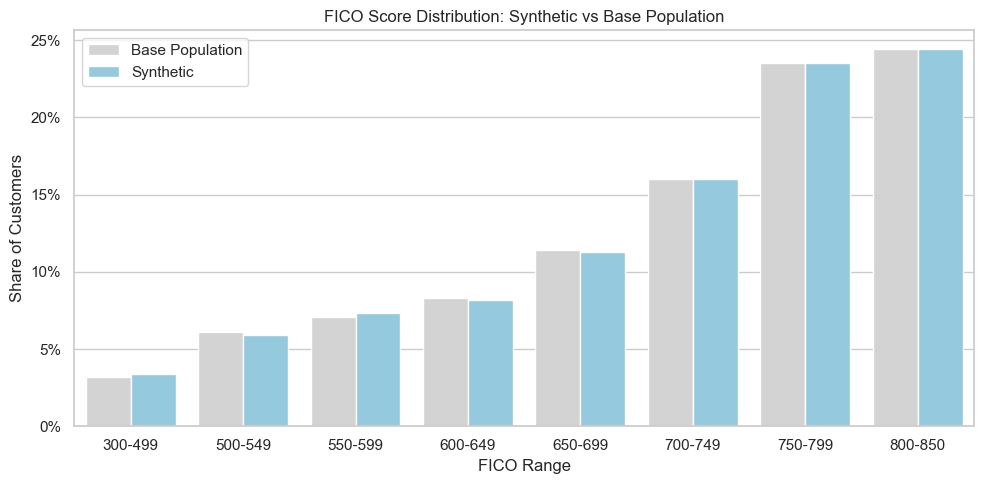

count    20000.0
mean       713.3
std        108.8
min        300.0
25%        651.0
50%        743.0
75%        798.0
max        850.0
Name: fico, dtype: float64

In [15]:
customer_view = df_time_series[df_time_series["month"] == df_time_series["month"].min()]

fico_bins = [300, 500, 550, 600, 650, 700, 750, 800, 851]
synthetic_share = (
    pd.cut(customer_view["fico"], bins=fico_bins, right=False)
    .value_counts(normalize=True, sort=False)
    .to_numpy()
)

fico_compare = pd.DataFrame({
    "range": list(fico_base_range_and_percentages.keys()) * 2,
    "share": np.concatenate([list(fico_base_range_and_percentages.values()), synthetic_share]),
    "source": ["Base Population"] * 8 + ["Synthetic"] * 8,
})

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=fico_compare, x="range", y="share", hue="source",
            palette={"Base Population": "lightgrey", "Synthetic": "skyblue"}, ax=ax)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_xlabel("FICO Range")
ax.set_ylabel("Share of Customers")
ax.set_title("FICO Score Distribution: Synthetic vs Base Population")
ax.legend(title="")
fig.tight_layout()
save_figure("eda_base_cust_fico_distribution.png")
plt.show()

customer_view["fico"].describe().round(1)

*Synthetic bucket shares match the population targets, with a median near 740 and scores bounded between 300 and 850.*

### Income Distribution

Incomes follow a log-normal distribution calibrated to the census median. A log-normal is symmetric in log space, but the census P10 and P90 are not symmetric around the median, so all three statistics cannot be matched at once. The median is matched exactly, and both P10 and P90 land somewhat above their census reference points.

Saved: outputs/figures/eda_base_cust_income_distribution.png


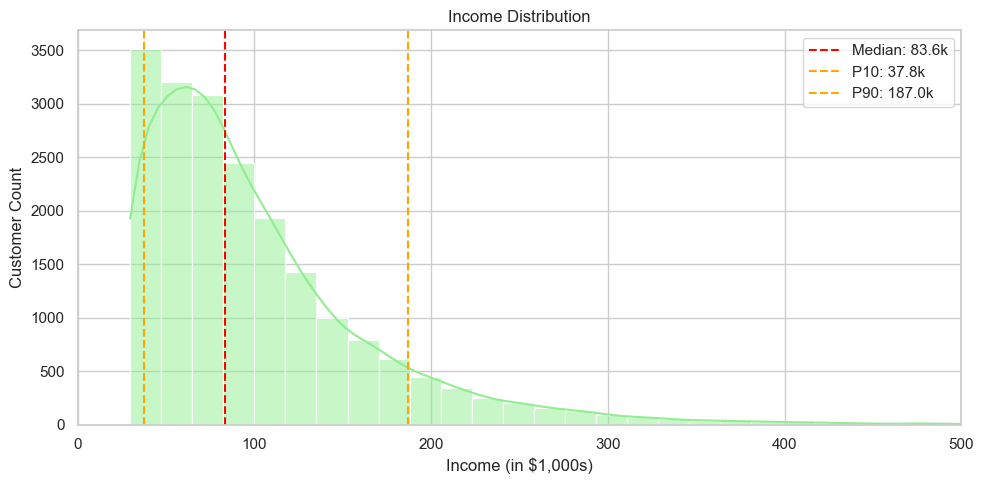

Census reference: median 83.7k, P10 33.0k, P90 160.0k
Synthetic:        median 83.6k, P10 37.8k, P90 187.0k


In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(customer_view["income"] / 1000, bins=60, kde=True, color="lightgreen", ax=ax)

income_quantiles = customer_view["income"].quantile([0.10, 0.50, 0.90]) / 1000
ax.axvline(income_quantiles[0.50], color="red", linestyle="--", label=f"Median: {income_quantiles[0.50]:.1f}k")
ax.axvline(income_quantiles[0.10], color="orange", linestyle="--", label=f"P10: {income_quantiles[0.10]:.1f}k")
ax.axvline(income_quantiles[0.90], color="orange", linestyle="--", label=f"P90: {income_quantiles[0.90]:.1f}k")

ax.set_xlim(0, 500)
ax.set_xlabel("Income (in $1,000s)")
ax.set_ylabel("Customer Count")
ax.set_title("Income Distribution")
ax.legend()
fig.tight_layout()
save_figure("eda_base_cust_income_distribution.png")
plt.show()

print("Census reference: median 83.7k, P10 33.0k, P90 160.0k")
print(f"Synthetic:        median {income_quantiles[0.50]:.1f}k, P10 {income_quantiles[0.10]:.1f}k, P90 {income_quantiles[0.90]:.1f}k")

### Debt-to-Income (DTI) Distribution

The inverse-U mapping concentrates DTI near its 45% ceiling for middle-income customers and at the 15% floor for customers far from the median. The grey band marks the typical conventional mortgage range of 36% to 45% (Fannie Mae).

Saved: outputs/figures/eda_base_cust_dti_distribution.png


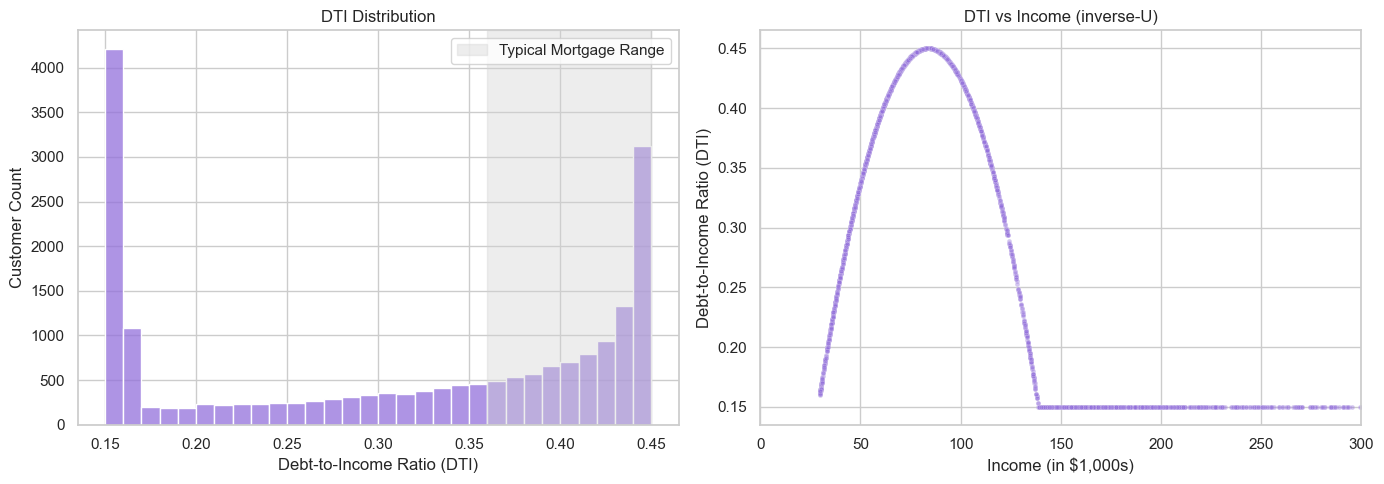

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(customer_view["dti"], bins=30, color="mediumpurple", ax=axes[0])
axes[0].axvspan(0.36, 0.45, color="lightgrey", alpha=0.4, label="Typical Mortgage Range")
axes[0].set_xlabel("Debt-to-Income Ratio (DTI)")
axes[0].set_ylabel("Customer Count")
axes[0].set_title("DTI Distribution")
axes[0].legend()

sns.scatterplot(data=customer_view.sample(3000, random_state=SEED), x=customer_view["income"] / 1000,
                y="dti", color="mediumpurple", alpha=0.4, s=12, ax=axes[1])
axes[1].set_xlim(0, 300)
axes[1].set_xlabel("Income (in $1,000s)")
axes[1].set_ylabel("Debt-to-Income Ratio (DTI)")
axes[1].set_title("DTI vs Income (inverse-U)")

fig.tight_layout()
save_figure("eda_base_cust_dti_distribution.png")
plt.show()

### FICO vs DTI Relationship

FICO and DTI are generated independently: DTI depends only on income. The scatter should therefore show no systematic relationship, which confirms credit quality and leverage enter the acceptance model as separate signals.

Saved: outputs/figures/eda_base_cust_fico_vs_dti.png


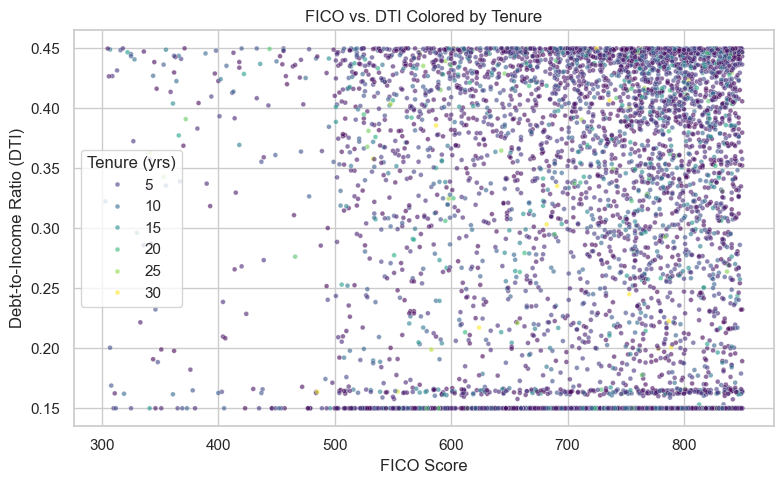

FICO-DTI correlation: -0.003


In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=customer_view.sample(5000, random_state=SEED),
    x="fico",
    y="dti",
    hue="tenure_yrs",
    palette="viridis",
    alpha=0.6,
    s=12,
    ax=ax,
)
ax.set_xlabel("FICO Score")
ax.set_ylabel("Debt-to-Income Ratio (DTI)")
ax.set_title("FICO vs. DTI Colored by Tenure")
ax.legend(title="Tenure (yrs)")
fig.tight_layout()
save_figure("eda_base_cust_fico_vs_dti.png")
plt.show()

print(f"FICO-DTI correlation: {customer_view['fico'].corr(customer_view['dti']):.3f}")

### Tenure Distribution

Tenure is drawn from an exponential distribution with a mean of 5 years, so the median customer has been with the bank for roughly 3.5 years and a minority have relationships beyond 10 years. These long-tenure customers are the ones protected by the loyalty rule in the optimization.

Saved: outputs/figures/eda_base_cust_tenure_distribution.png


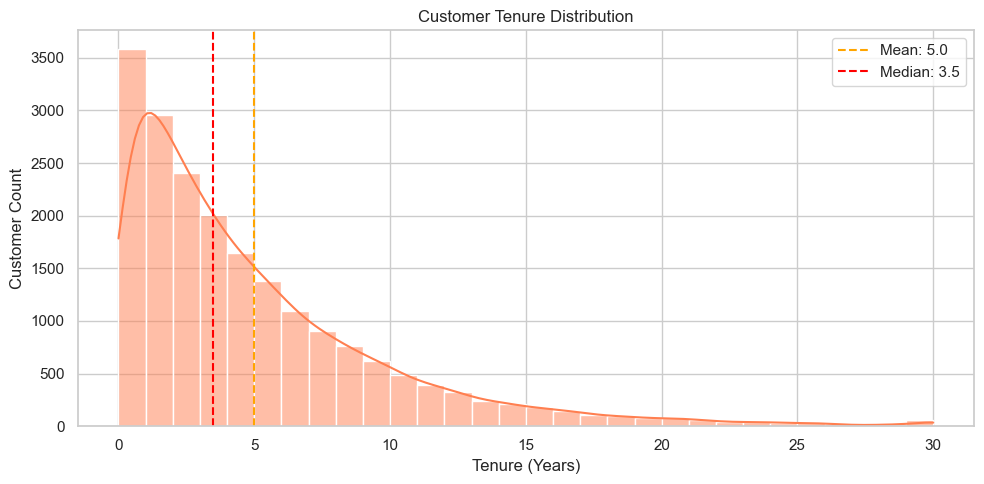

Share of customers with tenure >= 10 years: 13.2%


In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(customer_view["tenure_yrs"], bins=30, kde=True, color="coral", ax=ax)

mean_tenure = customer_view["tenure_yrs"].mean()
median_tenure = customer_view["tenure_yrs"].median()
ax.axvline(mean_tenure, color="orange", linestyle="--", label=f"Mean: {mean_tenure:.1f}")
ax.axvline(median_tenure, color="red", linestyle="--", label=f"Median: {median_tenure:.1f}")

ax.set_xlabel("Tenure (Years)")
ax.set_ylabel("Customer Count")
ax.set_title("Customer Tenure Distribution")
ax.legend()
fig.tight_layout()
save_figure("eda_base_cust_tenure_distribution.png")
plt.show()

print(f"Share of customers with tenure >= 10 years: {(customer_view['tenure_yrs'] >= 10).mean():.1%}")

### Mortgage Term Distribution

Terms are assigned with probabilities of 20% (15-year), 30% (20-year), and 50% (30-year).

Saved: outputs/figures/eda_base_mort_term_distribution.png


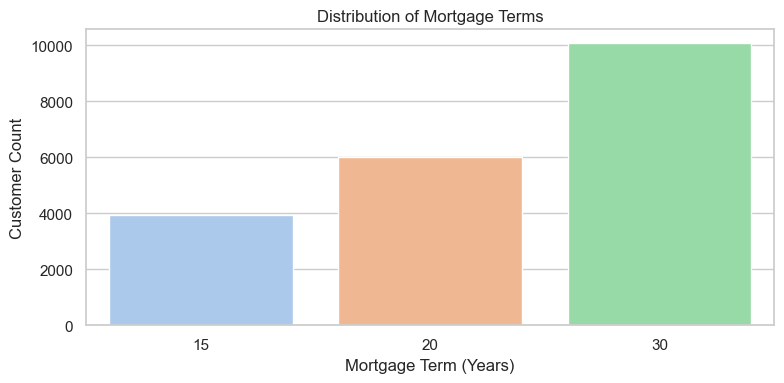

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x="term", data=customer_view, hue="term", palette="pastel", legend=False, ax=ax)
ax.set_xlabel("Mortgage Term (Years)")
ax.set_ylabel("Customer Count")
ax.set_title("Distribution of Mortgage Terms")
fig.tight_layout()
save_figure("eda_base_mort_term_distribution.png")
plt.show()

### Segment Composition

Segments are conditioned on customer profiles, so their attribute averages should differ in the expected directions: subprime customers have lower FICO, premium customers have higher FICO and income, and loyal customers have longer tenure.

In [21]:
segment_profile = (
    customer_view
    .groupby("segment")
    .agg(
        customers=("customer_id", "count"),
        mean_fico=("fico", "mean"),
        mean_income=("income", "mean"),
        mean_tenure_yrs=("tenure_yrs", "mean"),
        mean_loan_amount=("loan_amount", "mean"),
    )
    .reindex(SEGMENTS)
)
segment_profile["share"] = segment_profile["customers"] / segment_profile["customers"].sum()

display(segment_profile.round({"mean_fico": 0, "mean_income": 0, "mean_tenure_yrs": 1,
                               "mean_loan_amount": 0, "share": 3}))

,customers,mean_fico,mean_income,mean_tenure_yrs,mean_loan_amount,share
segment,,,,,,
shopper,5961,726.0,97751.0,4.3,266386.0,0.298
loyal,4010,724.0,96726.0,7.5,263393.0,0.200
risk_averse,4777,726.0,95771.0,4.4,262051.0,0.239
premium,2747,764.0,133208.0,4.4,367138.0,0.137
subprime,2505,584.0,98779.0,4.4,270926.0,0.125


### Offered Spread by Term

Historical offers vary around each term's target spread with a 30 bps standard deviation. This variation provides the price signal used to estimate customer rate sensitivity.

Saved: outputs/figures/eda_base_mort_offer_rate_spread.png


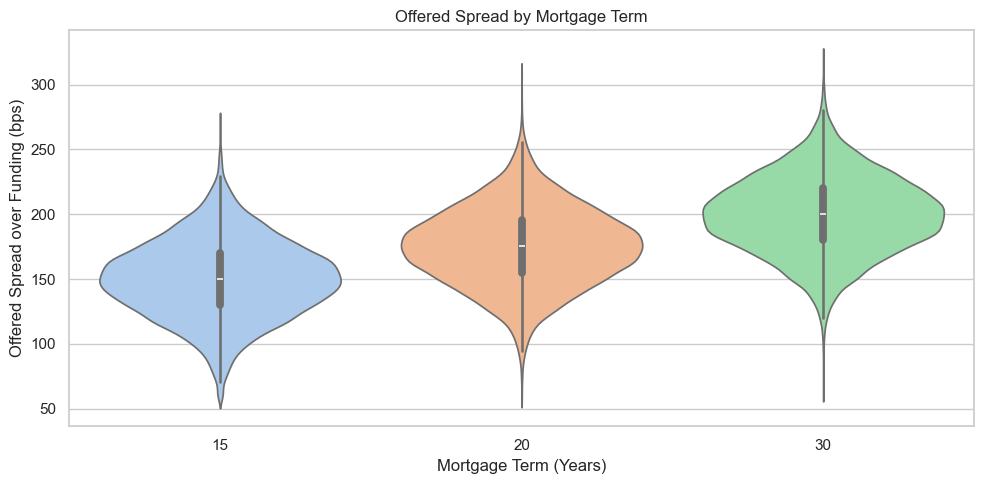

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(x="term", y="spread_bps", data=df_time_series.sample(50_000, random_state=SEED),
               hue="term", palette="pastel", legend=False, ax=ax)
ax.set_xlabel("Mortgage Term (Years)")
ax.set_ylabel("Offered Spread over Funding (bps)")
ax.set_title("Offered Spread by Mortgage Term")
fig.tight_layout()
save_figure("eda_base_mort_offer_rate_spread.png")
plt.show()

### Temporal Stability of Offered Rates

Average offered rates should remain stable across the panel, without introducing long-term drift.

Saved: outputs/figures/eda_base_avg_offer_rate_over_time.png


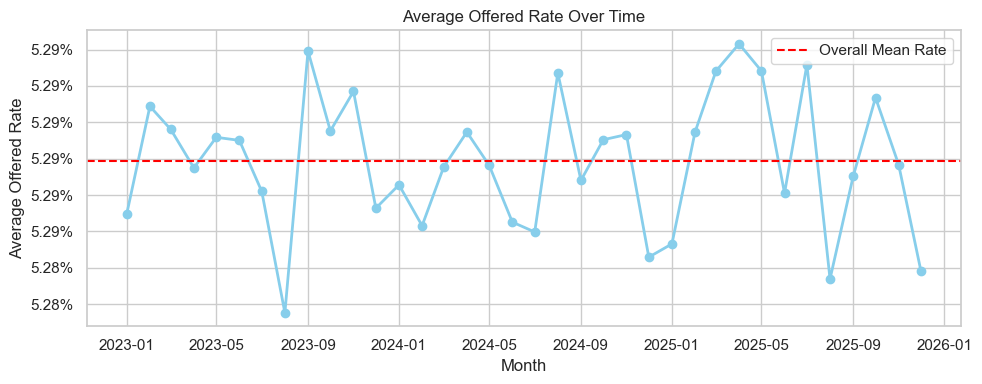

Monthly average range: 0.74 bps


In [23]:
monthly_avg = df_time_series.groupby("month")["offered_rate"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_avg.index, monthly_avg.values, marker="o", color="skyblue", linewidth=2)
ax.axhline(monthly_avg.mean(), color="red", linestyle="--", label="Overall Mean Rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.2%}"))
ax.set_xlabel("Month")
ax.set_ylabel("Average Offered Rate")
ax.set_title("Average Offered Rate Over Time")
ax.legend()
fig.tight_layout()
save_figure("eda_base_avg_offer_rate_over_time.png")
plt.show()

print(f"Monthly average range: {(monthly_avg.max() - monthly_avg.min()) * 10_000:.2f} bps")

*Monthly averages vary by well under 1 bps, so the panel has no drift and month can be treated as exchangeable in modeling.*

---

## Acceptance Probability Modeling

This section defines the behavioral acceptance function, generates binary outcomes, and trains models to predict acceptance.

**Objectives**

* Construct the acceptance function that maps customer characteristics and the offered spread to a probability.
* Generate binary acceptance labels for supervised learning.
* Train and compare Logistic Regression, Random Forest, and XGBoost.
* Select the model that best reproduces how acceptance responds to price, since that response is what the optimizer relies on.

### Synthetic Acceptance Probability Generator

Acceptance is driven by a logistic score built from four groups of effects.

**Price response**

Customers compare the offered spread with the term's target (market) spread. Every 100 bps above the target lowers the log-odds of acceptance by a customer-specific slope:

`beta = segment_beta x rate_elasticity x (0.6 + 0.8 x market_sensitivity)`

Segment betas range from 0.7 (loyal) to 2.4 (shopper). A convex penalty is added above the target spread, so acceptance falls faster once an offer becomes clearly uncompetitive.

**Customer quality**

Higher FICO and income raise acceptance, and higher DTI lowers it, reflecting customers with fewer refinancing alternatives versus those under financial stress.

**Relationship and behavior**

The loyalty factor raises acceptance, market sensitivity lowers it, and each segment has its own baseline propensity (loyal and premium highest, subprime lowest).

**Unobserved variation**

A persistent customer effect and a monthly noise term represent factors the bank cannot observe. Subprime customers have twice the monthly volatility of other segments.

The noise terms are stored with each row, so the function is deterministic given a row and a spread. This lets the same "true" probability be evaluated at any candidate price during optimization.

In [24]:
SEGMENT_INTERCEPT = {"shopper": -0.25, "loyal": 0.55, "risk_averse": 0.25, "premium": 0.15, "subprime": -0.35}
SEGMENT_RATE_BETA = {"shopper": 2.4, "loyal": 0.7, "risk_averse": 1.4, "premium": 1.0, "subprime": 1.8}


def add_monthly_noise(df, rng, base_volatility=0.15, subprime_volatility=0.30):
    """Attach the unobserved month-level noise term used by the acceptance function."""
    df = df.copy()
    volatility = np.where(df["segment"] == "subprime", subprime_volatility, base_volatility)
    df["row_noise"] = rng.normal(0, volatility)
    return df


def calculate_acceptance_probs(df, spread_bps=None):
    """
    True (data-generating) probability that a customer accepts a renewal offer.

    Parameters
    ----------
    df : pandas.DataFrame
        Requires fico, income, dti, loyalty_factor, rate_elasticity,
        market_sensitivity, segment, target_spread_bps, customer_effect,
        row_noise, and spread_bps (unless spread_bps is passed).
    spread_bps : array-like, optional
        Offered spread over funding in bps. Defaults to df["spread_bps"];
        pass candidate spreads to evaluate alternative prices.

    Returns
    -------
    np.array
        Acceptance probabilities, clipped to [0.02, 0.98].
    """
    spread = df["spread_bps"].to_numpy(float) if spread_bps is None else np.asarray(spread_bps, float)
    segment = df["segment"]

    # price response relative to the term's market spread (in percentage points)
    rate_gap = (spread - df["target_spread_bps"].to_numpy(float)) / 100
    rate_beta = (
        segment.map(SEGMENT_RATE_BETA).to_numpy()
        * df["rate_elasticity"].to_numpy()
        * (0.6 + 0.8 * df["market_sensitivity"].to_numpy())
    )
    price_effect = -rate_beta * rate_gap - 0.6 * np.maximum(rate_gap, 0) ** 2

    # customer quality
    quality_effect = (
        0.45 * (df["fico"].to_numpy() - 700) / 100
        - 1.5 * (df["dti"].to_numpy() - 0.30)
        + 0.25 * np.log(df["income"].to_numpy() / 83730)
    )

    # relationship and behavior
    behavior_effect = (
        segment.map(SEGMENT_INTERCEPT).to_numpy()
        + 1.2 * (df["loyalty_factor"].to_numpy() - 0.75)
        + 0.5 * (0.7 - df["market_sensitivity"].to_numpy())
    )

    score = (
        0.45
        + price_effect
        + quality_effect
        + behavior_effect
        + df["customer_effect"].to_numpy()
        + df["row_noise"].to_numpy()
    )

    return np.clip(expit(score), 0.02, 0.98)

*Computing true acceptance probabilities and simulating binary outcomes*

In [25]:
df_time_series = add_monthly_noise(df_time_series, rng)
df_time_series["accept_prob"] = calculate_acceptance_probs(df_time_series)
df_time_series["accepted"] = rng.binomial(1, df_time_series["accept_prob"])

print(f"Mean acceptance probability: {df_time_series['accept_prob'].mean():.3f}")
print(f"Observed acceptance rate:    {df_time_series['accepted'].mean():.3f}")

# the best AUC any model could achieve, since outcomes are random draws from these probabilities
oracle_auc = roc_auc_score(df_time_series["accepted"], df_time_series["accept_prob"])
print(f"Oracle AUC (true probabilities): {oracle_auc:.3f}")

Mean acceptance probability: 0.639
Observed acceptance rate:    0.639
Oracle AUC (true probabilities): 0.751


### Acceptance Probability Inspection

These checks confirm the generator produces the intended patterns before any model is trained.

#### True Price Response Curves by Segment

For each segment, the true acceptance probability is evaluated for the same customers while shifting their offer from 75 bps below to 75 bps above the target spread. This isolates the causal effect of price, which a simple binned plot of observed rates cannot do.

Saved: outputs/figures/accpt_prob_gen_acceptance_response_curve.png


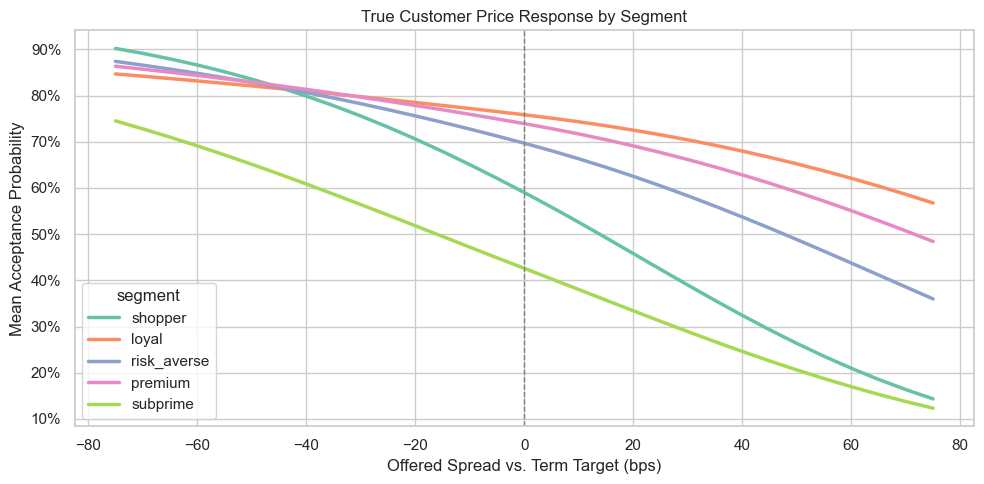

shift_bps,-50,0,50
segment,,,
shopper,0.836,0.590,0.263
loyal,0.821,0.758,0.652
risk_averse,0.828,0.697,0.488
premium,0.829,0.739,0.591
subprime,0.651,0.426,0.206


In [26]:
rate_shifts_bps = np.arange(-75, 76, 5)
sample_rows = customer_view.merge(
    df_time_series.loc[df_time_series["month"] == df_time_series["month"].min(),
                       ["customer_id", "row_noise"]],
    on="customer_id",
)

response_curves = pd.DataFrame([
    {
        "shift_bps": shift,
        "segment": seg,
        "accept_prob": calculate_acceptance_probs(
            group, spread_bps=group["target_spread_bps"] + shift
        ).mean(),
    }
    for shift in rate_shifts_bps
    for seg, group in sample_rows.groupby("segment")
])

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=response_curves, x="shift_bps", y="accept_prob", hue="segment",
             hue_order=SEGMENTS, palette=SEGMENT_PALETTE, linewidth=2.5, ax=ax)
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_xlabel("Offered Spread vs. Term Target (bps)")
ax.set_ylabel("Mean Acceptance Probability")
ax.set_title("True Customer Price Response by Segment")
fig.tight_layout()
save_figure("accpt_prob_gen_acceptance_response_curve.png")
plt.show()

display(
    response_curves[response_curves["shift_bps"].isin([-50, 0, 50])]
    .pivot(index="segment", columns="shift_bps", values="accept_prob")
    .reindex(SEGMENTS)
    .round(3)
)

*Shoppers and subprime customers are steeply price sensitive, while loyal and premium customers retain most of their acceptance under higher spreads. These differences are what make segment-specific pricing valuable.*

#### Acceptance by Term and Segment

,spread_bps,accept_prob,accepted
term,,,
15,150.054,0.642,0.642
20,174.957,0.639,0.637
30,200.028,0.638,0.639


Saved: outputs/figures/accpt_prob_gen_accept_prob_by_segment.png


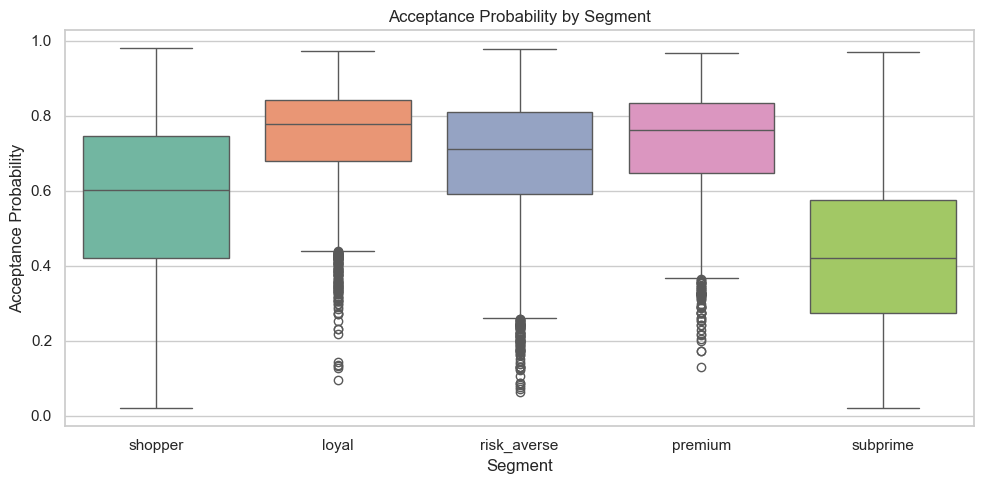

In [27]:
display(
    df_time_series
    .groupby("term")[["spread_bps", "accept_prob", "accepted"]]
    .mean()
    .round(3)
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_time_series.sample(20_000, random_state=SEED), x="segment", y="accept_prob",
            order=SEGMENTS, hue="segment", palette=SEGMENT_PALETTE, legend=False, ax=ax)
ax.set_xlabel("Segment")
ax.set_ylabel("Acceptance Probability")
ax.set_title("Acceptance Probability by Segment")
fig.tight_layout()
save_figure("accpt_prob_gen_accept_prob_by_segment.png")
plt.show()

#### Acceptance Probability Distribution

Saved: outputs/figures/accpt_prob_gen_base_distribution.png


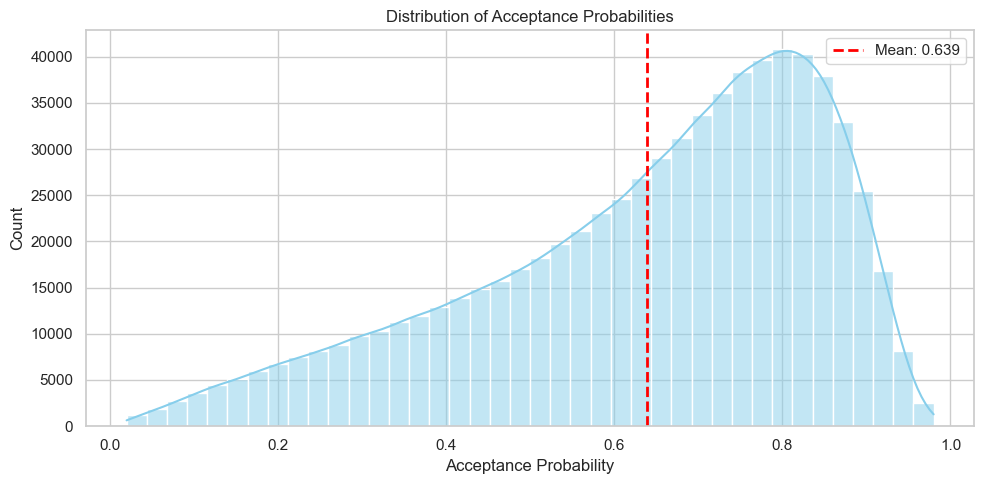

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_time_series["accept_prob"], bins=40, kde=True, color="skyblue", ax=ax)
mean_prob = df_time_series["accept_prob"].mean()
ax.axvline(mean_prob, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_prob:.3f}")
ax.set_xlabel("Acceptance Probability")
ax.set_ylabel("Count")
ax.set_title("Distribution of Acceptance Probabilities")
ax.legend()
fig.tight_layout()
save_figure("accpt_prob_gen_base_distribution.png")
plt.show()

#### Feature Correlations

Saved: outputs/figures/accpt_prob_gen_feature_correlations.png


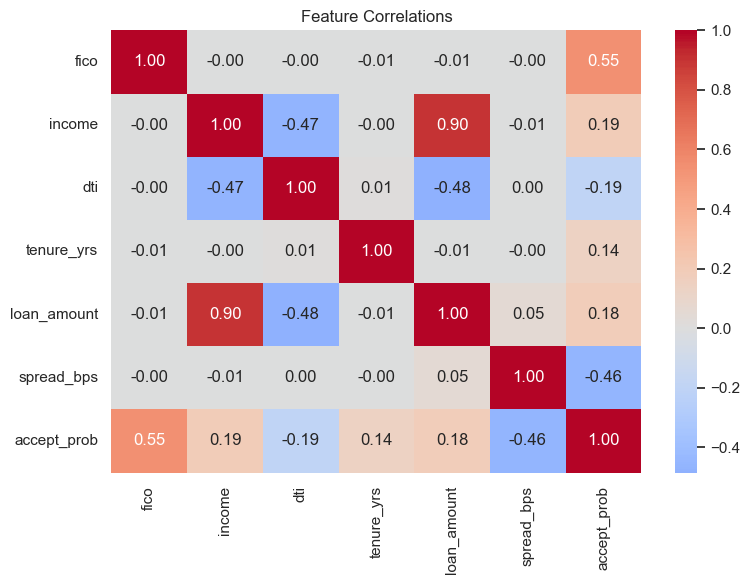

In [29]:
corr_cols = ["fico", "income", "dti", "tenure_yrs", "loan_amount", "spread_bps", "accept_prob"]
corr = df_time_series[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Feature Correlations")
fig.tight_layout()
save_figure("accpt_prob_gen_feature_correlations.png")
plt.show()

*Acceptance is positively correlated with FICO and tenure and negatively correlated with spread and DTI. Income and DTI show near-zero linear correlation despite their strong inverse-U relationship, a reminder that correlation only captures linear association.*

---

### Acceptance Probability Model Training and Evaluation

Models are trained on observable features only. Rate elasticity, market sensitivity, the customer effect, and monthly noise are excluded because a bank could not observe them.

The modeling question for pricing is broader than "who accepts". The optimizer moves each customer's price and asks how acceptance changes, so the model must also reproduce the *slope* of the price response, including how it differs by segment.

#### Data Preparation

The data is split by customer ID so all observations for a customer stay in either the training or test set, preventing leakage through the persistent customer effect.

The offered price enters as `spread_bps` (spread over funding) rather than the raw rate, since term-based funding costs otherwise confound the price signal.

In [30]:
numeric_features = ["fico", "income", "dti", "loan_amount", "tenure_yrs", "spread_bps"]
categorical_features = ["term", "segment"]
features = numeric_features + categorical_features
target = "accepted"

# splitting by unique customer IDs for train/test
customer_ids = df_time_series["customer_id"].unique()
train_ids, test_ids = train_test_split(customer_ids, test_size=0.3, random_state=SEED)

df_train = df_time_series[df_time_series["customer_id"].isin(train_ids)].copy()
df_test = df_time_series[df_time_series["customer_id"].isin(test_ids)].copy()

X_train, y_train = df_train[features], df_train[target]
X_test, y_test = df_test[features], df_test[target]

print(f"Train rows: {len(df_train):,} ({len(train_ids):,} customers)")
print(f"Test rows:  {len(df_test):,} ({len(test_ids):,} customers)")

Train rows: 504,000 (14,000 customers)
Test rows:  216,000 (6,000 customers)


#### Model Pipelines

* **Logistic Regression** includes `spread x segment` interaction terms so it can learn a separate price slope for each segment. Without them, a linear model forces every segment to share one slope.
* **Random Forest** uses moderately deep trees with a minimum leaf size to limit overfitting to noisy labels.
* **XGBoost** uses a monotone constraint so predicted acceptance can only fall as spread rises. This guarantees economically sensible price responses for the optimizer.

In [31]:
def add_rate_interactions(X):
    """Add spread x segment interaction columns so linear models can learn segment-specific price slopes."""
    X = X.copy()
    for seg in SEGMENTS:
        X[f"spread_x_{seg}"] = X["spread_bps"] * (X["segment"] == seg)
    return X


interaction_features = [f"spread_x_{seg}" for seg in SEGMENTS]

# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("interactions", FunctionTransformer(add_rate_interactions)),
    ("preprocessor", ColumnTransformer([
        ("num", StandardScaler(), numeric_features + interaction_features),
        ("cat", OneHotEncoder(sparse_output=False), categorical_features),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])

# tree models use unscaled features with names preserved for the monotone constraint
tree_preprocessor = ColumnTransformer(
    [
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(sparse_output=False), categorical_features),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=200,
        random_state=SEED,
        n_jobs=-1,
    )),
])

# XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        monotone_constraints={"spread_bps": -1},
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=-1,
    )),
])

model_pipelines = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline,
}

*Fitting each model and predicting on the test set*

In [32]:
for name, pipeline in model_pipelines.items():
    pipeline.fit(X_train, y_train)
    df_test[f"{name}_prob"] = pipeline.predict_proba(X_test)[:, 1]
    print(f"Fitted: {name}")

Fitted: Logistic Regression
Fitted: Random Forest
Fitted: XGBoost


#### Evaluation and Diagnostics

* **ROC-AUC** measures how well a model ranks customers by likelihood of acceptance. It is compared against the oracle AUC from the true probabilities, the ceiling imposed by random outcomes.
* **Brier score** and **log loss** measure probability accuracy.
* **Probability RMSE** compares predicted probabilities with the true ones, which is only possible because the data is synthetic.

In [33]:
def score_models(df, prob_columns):
    """Summarize discrimination and probability accuracy for each model's predictions."""
    rows = {}
    for name, col in prob_columns.items():
        rows[name] = {
            "ROC-AUC": roc_auc_score(df["accepted"], df[col]),
            "Brier Score": brier_score_loss(df["accepted"], df[col]),
            "Log Loss": log_loss(df["accepted"], df[col]),
            "Prob RMSE vs True": np.sqrt(np.mean((df[col] - df["accept_prob"]) ** 2)),
        }
    return pd.DataFrame(rows).T


prob_columns = {"Oracle (true probability)": "accept_prob"}
prob_columns.update({name: f"{name}_prob" for name in model_pipelines})

model_metrics = score_models(df_test, prob_columns)
display(model_metrics.round(4))

,ROC-AUC,Brier Score,Log Loss,Prob RMSE vs True
Oracle (true probability),0.7505,0.1883,0.5577,0.0000
Logistic Regression,0.7257,0.1961,0.5771,0.0894
Random Forest,0.7210,0.1986,0.5835,0.1017
XGBoost,0.7277,0.1956,0.5757,0.0858


#### Calibration Curves

Saved: outputs/figures/pred_accpt_prob_calibration_curves.png


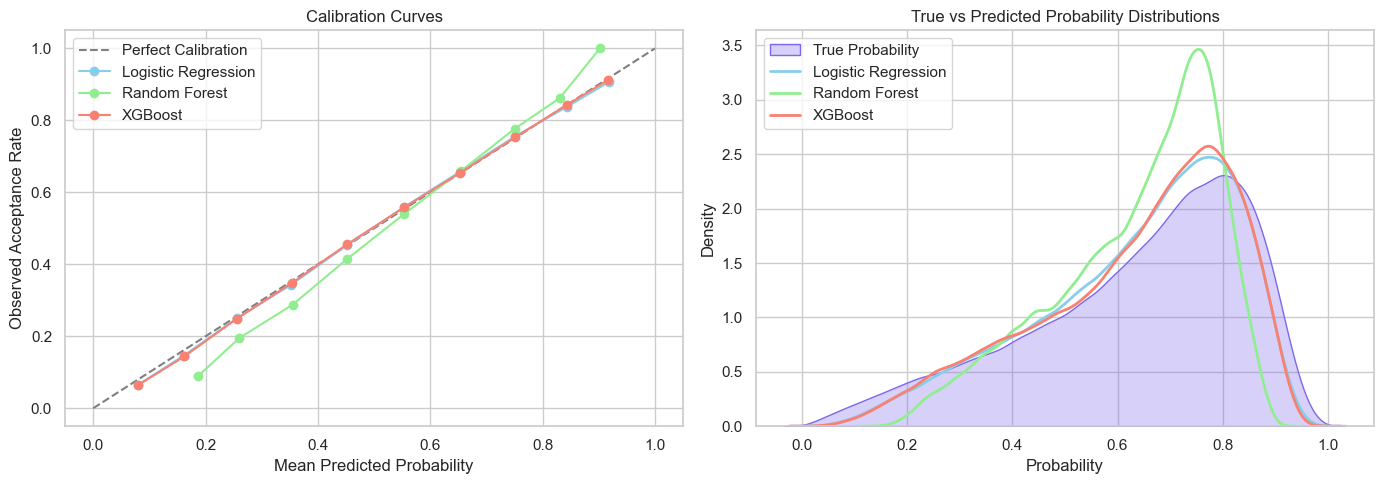

In [34]:
model_palette = {"Logistic Regression": "skyblue", "Random Forest": "lightgreen", "XGBoost": "salmon"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect Calibration")
for name, color in model_palette.items():
    prob_true, prob_pred = calibration_curve(df_test["accepted"], df_test[f"{name}_prob"], n_bins=10)
    axes[0].plot(prob_pred, prob_true, marker="o", color=color, label=name)
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Observed Acceptance Rate")
axes[0].set_title("Calibration Curves")
axes[0].legend()

sns.kdeplot(df_test["accept_prob"], fill=True, color="mediumslateblue", alpha=0.3,
            label="True Probability", ax=axes[1])
for name, color in model_palette.items():
    sns.kdeplot(df_test[f"{name}_prob"], color=color, linewidth=2, label=name, ax=axes[1])
axes[1].set_xlabel("Probability")
axes[1].set_ylabel("Density")
axes[1].set_title("True vs Predicted Probability Distributions")
axes[1].legend()

fig.tight_layout()
save_figure("pred_accpt_prob_calibration_curves.png")
plt.show()

*Predicted distributions are narrower than the true distribution because part of each customer's propensity is unobservable. Calibration curves show whether the probabilities are trustworthy on average, which matters because the optimizer multiplies them directly by dollar margins.*

#### ROC Curves

Saved: outputs/figures/pred_accpt_prob_roc_curves.png


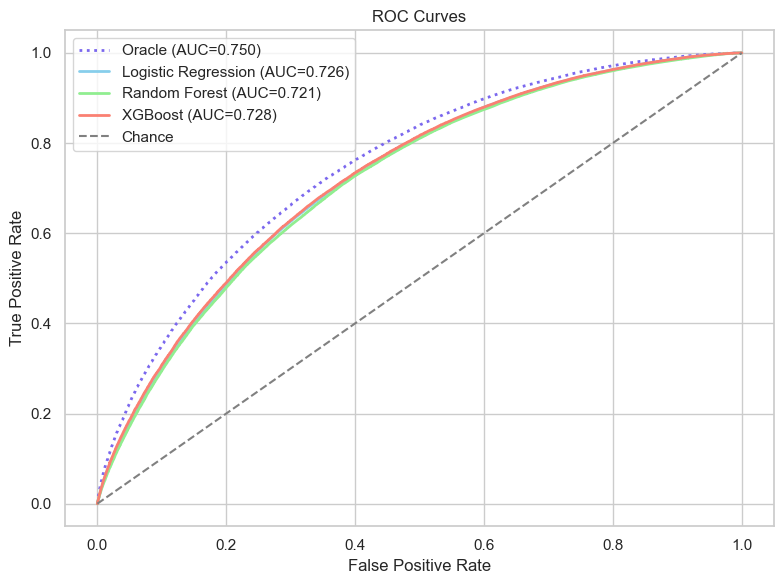

In [35]:
fig, ax = plt.subplots(figsize=(8, 6))

fpr, tpr, _ = roc_curve(df_test["accepted"], df_test["accept_prob"])
ax.plot(fpr, tpr, color="mediumslateblue", linestyle=":", linewidth=2,
        label=f"Oracle (AUC={model_metrics.loc['Oracle (true probability)', 'ROC-AUC']:.3f})")

for name, color in model_palette.items():
    fpr, tpr, _ = roc_curve(df_test["accepted"], df_test[f"{name}_prob"])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC={model_metrics.loc[name, 'ROC-AUC']:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves")
ax.legend()
fig.tight_layout()
save_figure("pred_accpt_prob_roc_curves.png")
plt.show()

#### Price Response Fidelity

This is the most important diagnostic for pricing. For test customers in the latest month, every customer's spread is shifted by the same amount and the mean predicted acceptance is compared with the mean true acceptance, by segment. A model can have a good AUC and still get these slopes wrong, which would mislead the optimizer.

Saved: outputs/figures/pred_accpt_prob_price_response_fidelity.png


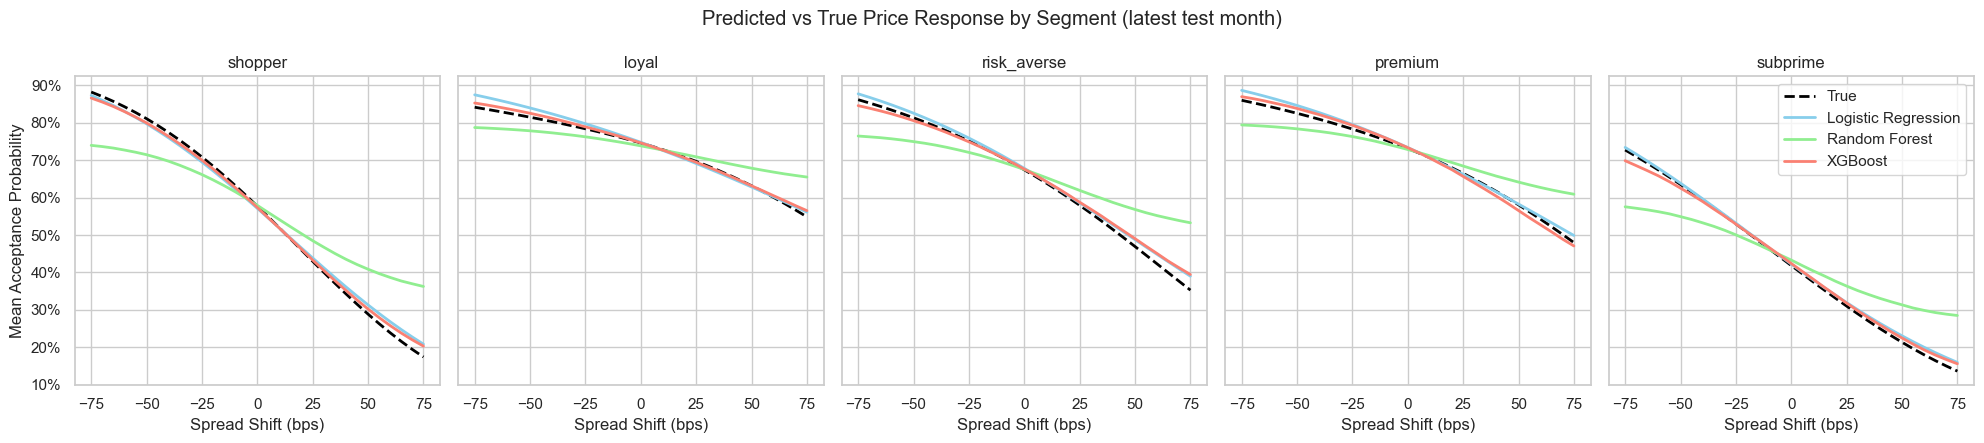

Change in mean acceptance per +10 bps (pp), between -50 and +50 bps:


,True,Logistic Regression,Random Forest,XGBoost
segment,,,,
shopper,-5.22,-4.84,-3.06,-4.97
loyal,-1.83,-2.11,-1.00,-1.94
risk_averse,-3.44,-3.38,-1.81,-3.15
premium,-2.44,-2.63,-1.42,-2.73
subprime,-4.21,-4.07,-2.36,-4.00


In [36]:
latest_month = df_test["month"].max()
df_last_month = df_test.loc[df_test["month"] == latest_month].reset_index(drop=True)

fidelity_rows = []
for shift in rate_shifts_bps:
    shifted = df_last_month.copy()
    shifted["spread_bps"] = shifted["spread_bps"] + shift
    shifted["True"] = calculate_acceptance_probs(shifted)
    for name, pipeline in model_pipelines.items():
        shifted[name] = pipeline.predict_proba(shifted[features])[:, 1]
    fidelity_rows.append(
        shifted.groupby("segment")[["True", *model_pipelines]].mean().assign(shift_bps=shift)
    )

price_fidelity = pd.concat(fidelity_rows).reset_index()

fig, axes = plt.subplots(1, len(SEGMENTS), figsize=(20, 4.5), sharey=True)
for ax, seg in zip(axes, SEGMENTS):
    seg_curve = price_fidelity[price_fidelity["segment"] == seg]
    ax.plot(seg_curve["shift_bps"], seg_curve["True"], color="black", linestyle="--", linewidth=2, label="True")
    for name, color in model_palette.items():
        ax.plot(seg_curve["shift_bps"], seg_curve[name], color=color, linewidth=2, label=name)
    ax.set_title(seg)
    ax.set_xlabel("Spread Shift (bps)")
axes[0].set_ylabel("Mean Acceptance Probability")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[-1].legend()
fig.suptitle("Predicted vs True Price Response by Segment (latest test month)")
fig.tight_layout()
save_figure("pred_accpt_prob_price_response_fidelity.png")
plt.show()

# average change in acceptance per +10 bps, true vs predicted
slope_table = (
    price_fidelity
    .groupby("segment")
    .apply(lambda g: (g.loc[g["shift_bps"] == 50, ["True", *model_pipelines]].to_numpy()
                      - g.loc[g["shift_bps"] == -50, ["True", *model_pipelines]].to_numpy())[0] / 10,
           include_groups=False)
)
slope_table = pd.DataFrame(slope_table.tolist(), index=slope_table.index,
                           columns=["True", *model_pipelines]).reindex(SEGMENTS)
print("Change in mean acceptance per +10 bps (pp), between -50 and +50 bps:")
display((slope_table * 100).round(2))

#### Tuning the Logistic Regression

Regularization strength is tuned with grouped cross-validation (customers never span folds), scored on log loss since the optimizer depends on probability accuracy rather than ranking alone. With roughly half a million training rows and only a handful of features, regularization is expected to have little effect, and the search confirms this: cross-validated log loss is essentially identical across the grid.

In [37]:
param_grid = {"model__C": [0.01, 0.1, 1.0, 10.0]}

grid_search = GridSearchCV(
    lr_pipeline,
    param_grid,
    scoring="neg_log_loss",
    cv=GroupKFold(n_splits=5),
    n_jobs=-1,
)
grid_search.fit(X_train, y_train, groups=df_train["customer_id"])

display(
    pd.DataFrame(grid_search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
    .assign(mean_log_loss=lambda d: -d["mean_test_score"])
    .drop(columns="mean_test_score")
    .round(5)
)
print("Best parameters:", grid_search.best_params_)

best_lr_pipeline = grid_search.best_estimator_
df_test["Tuned Logistic Regression_prob"] = best_lr_pipeline.predict_proba(X_test)[:, 1]
display(score_models(df_test, {"Logistic Regression": "Logistic Regression_prob",
                               "Tuned Logistic Regression": "Tuned Logistic Regression_prob"}).round(4))

,param_model__C,std_test_score,mean_log_loss
0,0.01,0.00178,0.57514
1,0.10,0.00177,0.57510
2,1.00,0.00177,0.57510
3,10.00,0.00177,0.57510


Best parameters: {'model__C': 10.0}


,ROC-AUC,Brier Score,Log Loss,Prob RMSE vs True
Logistic Regression,0.7257,0.1961,0.5771,0.0894
Tuned Logistic Regression,0.7257,0.1961,0.5771,0.0894


#### Final Acceptance Model Selection

The models are compared on the criteria the optimizer depends on:

* **Discrimination and probability accuracy:** the three models are within a narrow band of each other, about 0.02 to 0.03 AUC below the oracle ceiling. XGBoost is marginally ahead on every metric.
* **Price response fidelity:** the interaction-based Logistic Regression and the monotone XGBoost both recover segment-specific slopes closely. Random Forest roughly halves every slope: averaging many trees, each splitting on whichever feature is most informative locally, dilutes the price effect.
* **Interpretability and stability:** Logistic Regression produces smooth, monotone price curves with coefficients that can be explained directly to pricing and governance teams.

Logistic Regression and XGBoost are close enough on statistical metrics that interpretability decides: the (tuned) Logistic Regression is selected as the optimization engine. All models are also run through the optimizer in the evaluation section to confirm the choice on business outcomes.

In [38]:
selected_model_name = "Tuned Logistic Regression"
selected_pipeline = best_lr_pipeline

# coefficients on the spread terms show the learned price slope for each segment
lr_model = selected_pipeline.named_steps["model"]
lr_feature_names = selected_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(lr_model.coef_[0], index=lr_feature_names)
display(coefficients.filter(like="spread").round(4).to_frame("standardized coefficient"))

,standardized coefficient
num__spread_bps,-0.6281
num__spread_x_shopper,-0.6270
num__spread_x_loyal,0.4041
num__spread_x_risk_averse,-0.0082
num__spread_x_premium,0.1726
num__spread_x_subprime,-0.1531


---

## Mortgage Renewal Offer Rate Optimization

In this section, predicted acceptance probabilities are translated into pricing decisions.

**Objectives**

* Generate a grid of candidate rate adjustments for each customer.
* Compute expected annual margin at each candidate using predicted acceptance.
* Apply business rules, then select the margin-maximizing rate.
* Evaluate decisions against the true acceptance function and an oracle benchmark.

### Objective and Business Rules

For each customer and candidate spread `s`:

`expected annual margin = s x loan amount x P(accept | s)`

A rejected offer earns no margin, since the customer leaves at renewal. The margin uses the full principal as a simplified annual approximation.

**Business rules**

* **Search range:** adjustments from -75 to +50 bps in 1 bps steps.
* **Spread floor:** offered spread must stay at least 75 bps above funding to cover operating costs and credit risk.
* **Loyalty protection:** loyal-segment customers and customers with 10+ years of tenure can receive at most a +15 bps increase. This protects long-standing relationships even when the model predicts they would tolerate more.

In [39]:
PRICING_RULES = {
    "max_down_bps": 75,
    "max_up_bps": 50,
    "step_bps": 1,
    "min_spread_bps": 75,
    "loyalty_max_up_bps": 15,
    "loyalty_min_tenure_yrs": 10,
}


def optimize_offer_rates(customers, prob_fn, rules=PRICING_RULES):
    """
    Choose a margin-maximizing rate adjustment for every customer.

    Parameters
    ----------
    customers : pandas.DataFrame
        One row per customer with model features, loan_amount,
        funding_rate, and spread_bps (the current offer).
    prob_fn : callable
        Maps a candidate DataFrame (same columns, spread_bps replaced)
        to acceptance probabilities.
    rules : dict
        Search range and business rule settings.

    Returns
    -------
    pandas.DataFrame
        Per customer: change_bps, optimal_spread_bps, optimal_rate,
        predicted acceptance and expected annual margin at the
        current and optimal offer, and whether the rate cap or floor bound.
    """
    grid = np.arange(-rules["max_down_bps"], rules["max_up_bps"] + 1, rules["step_bps"])
    n, g = len(customers), len(grid)

    # one row per customer x candidate adjustment
    candidates = customers.loc[customers.index.repeat(g)].reset_index(drop=True)
    candidates["change_bps"] = np.tile(grid, n)
    candidates["spread_bps"] = candidates["spread_bps"] + candidates["change_bps"]

    # business rules
    protected = (
        (candidates["segment"] == "loyal")
        | (candidates["tenure_yrs"] >= rules["loyalty_min_tenure_yrs"])
    )
    max_up = np.where(protected, rules["loyalty_max_up_bps"], rules["max_up_bps"])
    feasible = (
        (candidates["spread_bps"] >= rules["min_spread_bps"])
        & (candidates["change_bps"] <= max_up)
    ).to_numpy()

    p_accept = prob_fn(candidates)
    margin = candidates["spread_bps"].to_numpy() / 10_000 * candidates["loan_amount"].to_numpy() * p_accept

    # selecting the best feasible candidate per customer
    margin_grid = np.where(feasible, margin, -np.inf).reshape(n, g)
    best_idx = margin_grid.argmax(axis=1)
    rows = np.arange(n)
    current_idx = int(np.flatnonzero(grid == 0)[0])

    p_grid = p_accept.reshape(n, g)
    change = grid[best_idx]
    optimal_spread = customers["spread_bps"].to_numpy() + change

    return pd.DataFrame({
        "customer_id": customers["customer_id"].to_numpy(),
        "change_bps": change,
        "optimal_spread_bps": optimal_spread,
        "optimal_rate": customers["funding_rate"].to_numpy() + optimal_spread / 10_000,
        "pred_accept_current": p_grid[:, current_idx],
        "pred_accept_optimal": p_grid[rows, best_idx],
        "pred_margin_current": margin.reshape(n, g)[:, current_idx],
        "pred_margin_optimal": margin_grid[rows, best_idx],
        "at_upper_limit": change == max_up.reshape(n, g)[:, 0],
        "at_lower_limit": (change == -rules["max_down_bps"])
                          | (optimal_spread - rules["step_bps"] < rules["min_spread_bps"]),
        "loyalty_protected": protected.to_numpy().reshape(n, g)[:, 0],
    })

### Generating Optimized Offers

The optimizer is applied to every held-out test customer in the latest month, so recommendations are made for customers the model never saw in training.

In [40]:
def model_prob_fn(pipeline):
    """Wrap a fitted pipeline as a probability function for the optimizer."""
    return lambda candidates: pipeline.predict_proba(candidates[features])[:, 1]


def true_prob_fn(candidates):
    """Ground-truth acceptance, used for the oracle benchmark."""
    return calculate_acceptance_probs(candidates)


optimized_offers = optimize_offer_rates(df_last_month, model_prob_fn(selected_pipeline))
df_optimized = df_last_month.merge(optimized_offers, on="customer_id", validate="one_to_one")

print(f"Latest test month: {latest_month:%Y-%m}")
print(f"Customers optimized: {len(df_optimized):,}")
print(f"Loyalty-protected customers: {df_optimized['loyalty_protected'].mean():.1%}")
display(df_optimized["change_bps"].describe().round(1).to_frame("recommended change (bps)").T)

Latest test month: 2025-12
Customers optimized: 6,000
Loyalty-protected customers: 27.9%


,count,mean,std,min,25%,50%,75%,max
recommended change (bps),6000.0,-9.2,34.6,-75.0,-35.0,-3.0,15.0,50.0


### Inspecting Individual Customers

For one customer from each segment, the chart shows predicted acceptance and expected annual margin across the full candidate grid. The selected rate sits where the margin curve peaks: each additional basis point earns more per accepted loan, but loses enough acceptance that total expected margin eventually declines.

Saved: outputs/figures/mort_rate_opt_customer_margin_curves.png


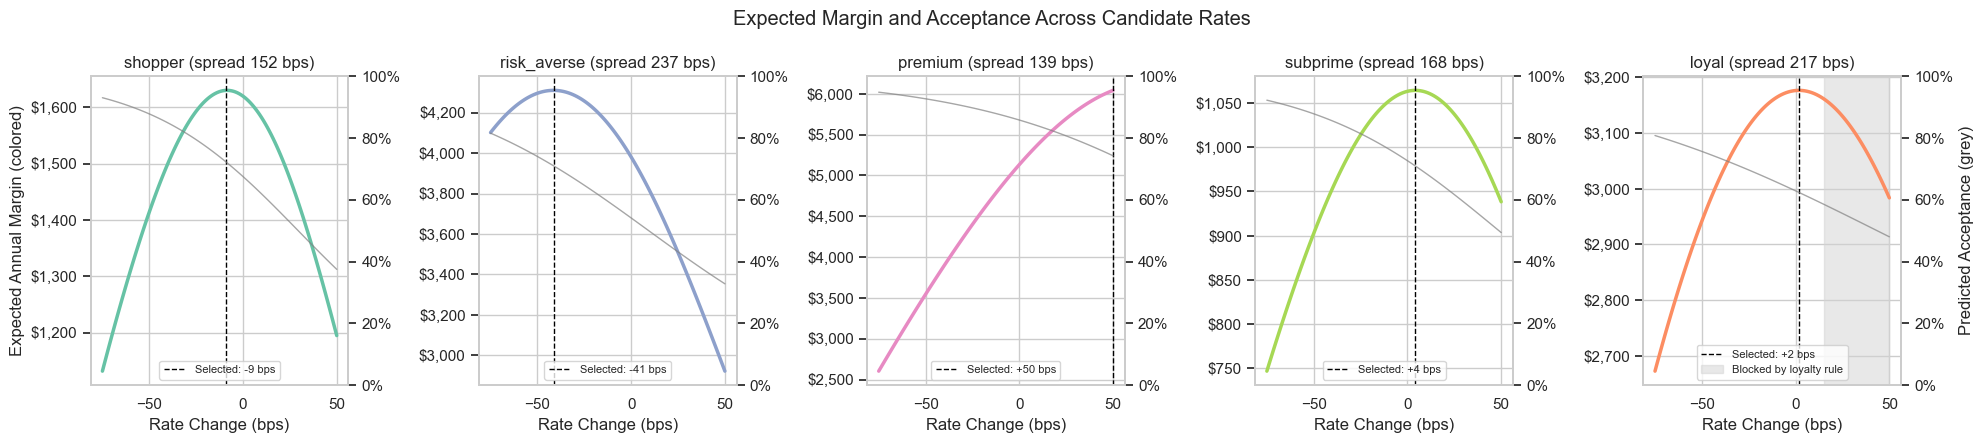

In [41]:
example_customers = (
    df_optimized[~df_optimized["loyalty_protected"]]
    .groupby("segment")
    .head(1)
    .set_index("segment")
    .reindex([s for s in SEGMENTS if s != "loyal"])
)
example_customers = pd.concat([
    example_customers,
    df_optimized[df_optimized["segment"] == "loyal"].head(1).set_index("segment"),
])

grid = np.arange(-PRICING_RULES["max_down_bps"], PRICING_RULES["max_up_bps"] + 1)
fig, axes = plt.subplots(1, len(example_customers), figsize=(20, 4.5))

for ax, (seg, cust) in zip(axes, example_customers.iterrows()):
    curve = pd.DataFrame([cust] * len(grid)).reset_index(drop=True)
    curve["segment"] = seg
    curve["spread_bps"] = cust["spread_bps"] + grid
    p = selected_pipeline.predict_proba(curve[features])[:, 1]
    margin = curve["spread_bps"] / 10_000 * cust["loan_amount"] * p

    ax.plot(grid, margin, color=SEGMENT_PALETTE[seg], linewidth=2.5)
    ax.axvline(cust["change_bps"], color="black", linestyle="--", linewidth=1,
               label=f"Selected: {cust['change_bps']:+.0f} bps")
    if cust["loyalty_protected"]:
        ax.axvspan(PRICING_RULES["loyalty_max_up_bps"], grid.max(), color="lightgrey", alpha=0.5,
                   label="Blocked by loyalty rule")
    ax.set_title(f"{seg} (spread {cust['spread_bps']:.0f} bps)")
    ax.set_xlabel("Rate Change (bps)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
    ax.legend(loc="lower center", fontsize=8)

    twin = ax.twinx()
    twin.plot(grid, p, color="grey", linewidth=1, alpha=0.7)
    twin.set_ylim(0, 1)
    twin.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    twin.grid(False)

axes[0].set_ylabel("Expected Annual Margin (colored)")
twin.set_ylabel("Predicted Acceptance (grey)")
fig.suptitle("Expected Margin and Acceptance Across Candidate Rates")
fig.tight_layout()
save_figure("mort_rate_opt_customer_margin_curves.png")
plt.show()

---

## Optimization Evaluation and Insights

Predicted margins describe what the model *believes* will happen. Because this dataset is synthetic, we can instead evaluate each pricing strategy with the true acceptance function. Three strategies are compared for the same customers:

* **Current:** the existing historical offer.
* **Model-optimized:** prices chosen using the selected model.
* **Oracle:** prices chosen using the true acceptance function, under the same business rules. This is the best achievable result and sets the benchmark.

The share of the oracle's uplift captured by the model is the clearest measure of how much value the predictive model delivers.

In [42]:
def evaluate_true_outcomes(customers, change_bps):
    """Score a set of rate changes with the true acceptance function."""
    new_spread = customers["spread_bps"].to_numpy() + change_bps
    p_true = calculate_acceptance_probs(customers, spread_bps=new_spread)
    margin = new_spread / 10_000 * customers["loan_amount"].to_numpy() * p_true
    return p_true, margin


oracle_offers = optimize_offer_rates(df_last_month, true_prob_fn)

df_optimized["true_accept_current"], df_optimized["true_margin_current"] = evaluate_true_outcomes(
    df_optimized, np.zeros(len(df_optimized)))
df_optimized["true_accept_optimized"], df_optimized["true_margin_optimized"] = evaluate_true_outcomes(
    df_optimized, df_optimized["change_bps"].to_numpy())
df_optimized["oracle_change_bps"] = oracle_offers["change_bps"].to_numpy()
df_optimized["true_accept_oracle"], df_optimized["true_margin_oracle"] = evaluate_true_outcomes(
    df_optimized, df_optimized["oracle_change_bps"].to_numpy())
df_optimized["true_incremental_margin"] = (
    df_optimized["true_margin_optimized"] - df_optimized["true_margin_current"]
)

#### Strategy Comparison Across Models

*Each candidate model drives the optimizer and is scored on true outcomes. This confirms model selection on the metric the business cares about.*

In [43]:
baseline_margin = df_optimized["true_margin_current"].sum()
oracle_uplift = df_optimized["true_margin_oracle"].sum() - baseline_margin

strategy_pipelines = {**model_pipelines, "Tuned Logistic Regression": best_lr_pipeline}
strategy_rows = []

for name, pipeline in strategy_pipelines.items():
    offers = optimize_offer_rates(df_last_month, model_prob_fn(pipeline))
    p_true, margin = evaluate_true_outcomes(df_last_month, offers["change_bps"].to_numpy())
    strategy_rows.append({
        "strategy": name,
        "avg_change_bps": offers["change_bps"].mean(),
        "share_at_upper_limit": offers["at_upper_limit"].mean(),
        "true_acceptance": p_true.mean(),
        "true_annual_margin": margin.sum(),
        "uplift_vs_current": margin.sum() - baseline_margin,
    })

strategy_rows.append({
    "strategy": "Oracle (true function)",
    "avg_change_bps": df_optimized["oracle_change_bps"].mean(),
    "share_at_upper_limit": oracle_offers["at_upper_limit"].mean(),
    "true_acceptance": df_optimized["true_accept_oracle"].mean(),
    "true_annual_margin": df_optimized["true_margin_oracle"].sum(),
    "uplift_vs_current": oracle_uplift,
})

strategy_comparison = pd.DataFrame(strategy_rows).set_index("strategy")
strategy_comparison["uplift_pct"] = strategy_comparison["uplift_vs_current"] / baseline_margin
strategy_comparison["share_of_oracle_uplift"] = strategy_comparison["uplift_vs_current"] / oracle_uplift

print(f"Current strategy: true acceptance {df_optimized['true_accept_current'].mean():.3f}, "
      f"annual margin ${baseline_margin:,.0f}")
display(strategy_comparison.style.format({
    "avg_change_bps": "{:+.1f}",
    "share_at_upper_limit": "{:.1%}",
    "true_acceptance": "{:.3f}",
    "true_annual_margin": "${:,.0f}",
    "uplift_vs_current": "${:,.0f}",
    "uplift_pct": "{:.1%}",
    "share_of_oracle_uplift": "{:.1%}",
}))

Current strategy: true acceptance 0.634, annual margin $19,624,740


,avg_change_bps,share_at_upper_limit,true_acceptance,true_annual_margin,uplift_vs_current,uplift_pct,share_of_oracle_uplift
strategy,,,,,,,
Logistic Regression,-9.2,23.8%,0.707,"$21,416,260","$1,791,520",9.1%,86.5%
Random Forest,+11.3,34.7%,0.612,"$20,355,593","$730,853",3.7%,35.3%
XGBoost,-6.5,15.9%,0.695,"$21,347,317","$1,722,577",8.8%,83.2%
Tuned Logistic Regression,-9.2,23.8%,0.707,"$21,416,346","$1,791,606",9.1%,86.5%
Oracle (true function),-6.8,25.6%,0.707,"$21,695,302","$2,070,563",10.6%,100.0%


#### Recommended Rate Changes by Segment

The distribution of recommended changes shows how the optimizer differentiates pricing: price-sensitive segments receive discounts, while less sensitive segments receive increases, limited by the loyalty rule where it applies.

Saved: outputs/figures/mort_rate_opt_rate_change_by_segment.png


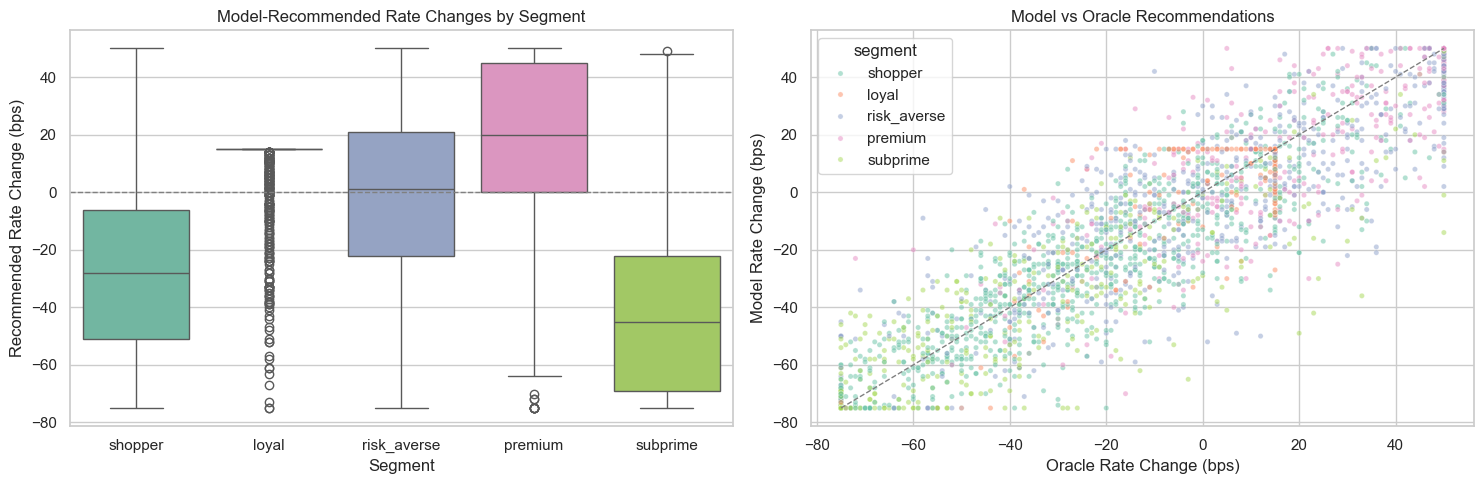

Correlation between model and oracle changes: 0.914


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df_optimized, x="segment", y="change_bps", order=SEGMENTS,
            hue="segment", palette=SEGMENT_PALETTE, legend=False, ax=axes[0])
axes[0].axhline(0, color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("Recommended Rate Change (bps)")
axes[0].set_title("Model-Recommended Rate Changes by Segment")

agreement = df_optimized.sample(min(3000, len(df_optimized)), random_state=SEED)
sns.scatterplot(data=agreement, x="oracle_change_bps", y="change_bps", hue="segment",
                hue_order=SEGMENTS, palette=SEGMENT_PALETTE, alpha=0.5, s=14, ax=axes[1])
lims = [-PRICING_RULES["max_down_bps"], PRICING_RULES["max_up_bps"]]
axes[1].plot(lims, lims, color="grey", linestyle="--", linewidth=1)
axes[1].set_xlabel("Oracle Rate Change (bps)")
axes[1].set_ylabel("Model Rate Change (bps)")
axes[1].set_title("Model vs Oracle Recommendations")

fig.tight_layout()
save_figure("mort_rate_opt_rate_change_by_segment.png")
plt.show()

print(f"Correlation between model and oracle changes: "
      f"{df_optimized['change_bps'].corr(df_optimized['oracle_change_bps']):.3f}")

#### Rate and Margin Distributions

The left panel compares current and optimized offered rates. The right panel compares the true expected annual margin per customer before and after optimization.

Saved: outputs/figures/mort_rate_opt_rate_profit_combo.png


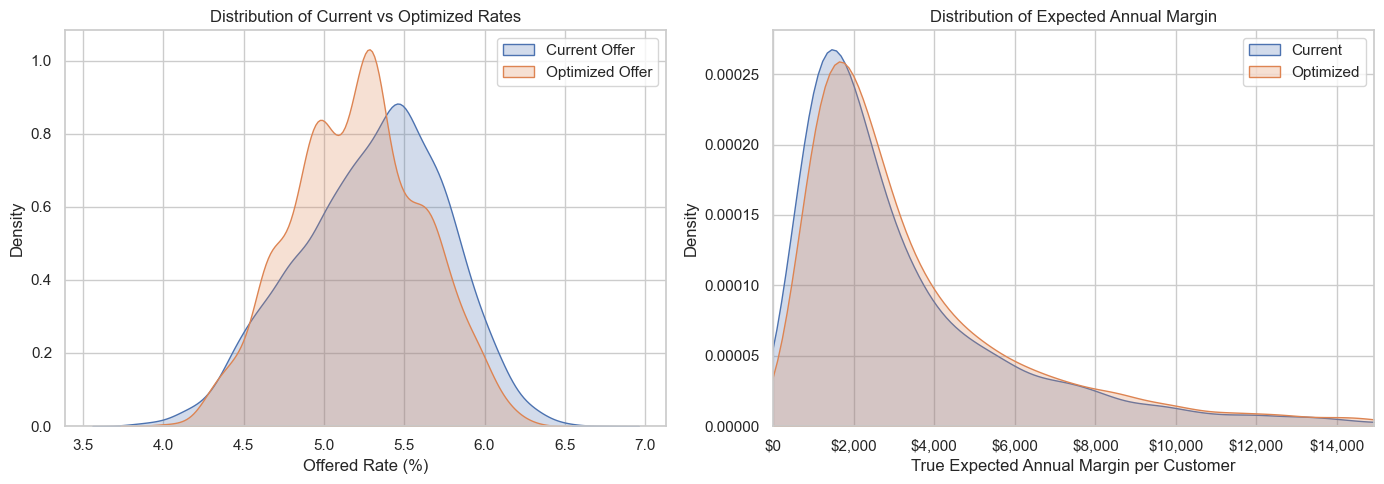

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(df_optimized["offered_rate"] * 100, fill=True, label="Current Offer", ax=axes[0])
sns.kdeplot(df_optimized["optimal_rate"] * 100, fill=True, label="Optimized Offer", ax=axes[0])
axes[0].set_xlabel("Offered Rate (%)")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution of Current vs Optimized Rates")
axes[0].legend()

sns.kdeplot(df_optimized["true_margin_current"], fill=True, label="Current", ax=axes[1])
sns.kdeplot(df_optimized["true_margin_optimized"], fill=True, label="Optimized", ax=axes[1])
axes[1].set_xlim(0, df_optimized["true_margin_optimized"].quantile(0.99))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].set_xlabel("True Expected Annual Margin per Customer")
axes[1].set_ylabel("Density")
axes[1].set_title("Distribution of Expected Annual Margin")
axes[1].legend()

fig.tight_layout()
save_figure("mort_rate_opt_rate_profit_combo.png")
plt.show()

#### Portfolio and Segment Summaries

In [46]:
portfolio_summary = pd.DataFrame([{
    "customers": len(df_optimized),
    "avg_rate_change_bps": df_optimized["change_bps"].mean(),
    "median_rate_change_bps": df_optimized["change_bps"].median(),
    "share_rate_increase": (df_optimized["change_bps"] > 0).mean(),
    "share_rate_decrease": (df_optimized["change_bps"] < 0).mean(),
    "true_acceptance_current": df_optimized["true_accept_current"].mean(),
    "true_acceptance_optimized": df_optimized["true_accept_optimized"].mean(),
    "true_annual_margin_current": df_optimized["true_margin_current"].sum(),
    "true_annual_margin_optimized": df_optimized["true_margin_optimized"].sum(),
    "true_incremental_annual_margin": df_optimized["true_incremental_margin"].sum(),
    "uplift_pct": df_optimized["true_incremental_margin"].sum() / baseline_margin,
    "share_of_oracle_uplift": df_optimized["true_incremental_margin"].sum() / oracle_uplift,
}])

display(portfolio_summary.T.rename(columns={0: "value"}).round(3))

,value
customers,6.000000e+03
avg_rate_change_bps,-9.173000e+00
median_rate_change_bps,-3.000000e+00
share_rate_increase,4.700000e-01
share_rate_decrease,5.230000e-01
true_acceptance_current,6.340000e-01
true_acceptance_optimized,7.070000e-01
true_annual_margin_current,1.962474e+07
true_annual_margin_optimized,2.141635e+07
true_incremental_annual_margin,1.791606e+06


In [47]:
segment_summary = (
    df_optimized
    .groupby("segment")
    .agg(
        customers=("customer_id", "nunique"),
        loyalty_protected=("loyalty_protected", "mean"),
        avg_rate_change_bps=("change_bps", "mean"),
        oracle_avg_rate_change_bps=("oracle_change_bps", "mean"),
        true_acceptance_current=("true_accept_current", "mean"),
        true_acceptance_optimized=("true_accept_optimized", "mean"),
        true_margin_current=("true_margin_current", "sum"),
        true_margin_optimized=("true_margin_optimized", "sum"),
        true_margin_oracle=("true_margin_oracle", "sum"),
    )
    .reindex(SEGMENTS)
)
segment_summary["true_incremental_margin"] = (
    segment_summary["true_margin_optimized"] - segment_summary["true_margin_current"]
)
segment_summary["uplift_pct"] = segment_summary["true_incremental_margin"] / segment_summary["true_margin_current"]
segment_summary["share_of_oracle_uplift"] = (
    segment_summary["true_incremental_margin"]
    / (segment_summary["true_margin_oracle"] - segment_summary["true_margin_current"])
)

display(segment_summary.round(3))

,customers,loyalty_protected,avg_rate_change_bps,oracle_avg_rate_change_bps,true_acceptance_current,true_acceptance_optimized,true_margin_current,true_margin_optimized,true_margin_oracle,true_incremental_margin,uplift_pct,share_of_oracle_uplift
segment,,,,,,,,,,,,
shopper,1807,0.092,-27.406,-24.451,0.577,0.747,5054904.969,5759490.098,5856944.744,704585.129,0.139,0.878
loyal,1210,1.000,10.574,10.345,0.746,0.731,4369251.340,4578673.262,4589869.340,209421.923,0.048,0.949
risk_averse,1390,0.096,-0.646,2.612,0.674,0.693,4481911.141,4747876.278,4826803.259,265965.137,0.059,0.771
premium,818,0.110,18.213,20.631,0.731,0.697,4110085.630,4408831.151,4461374.369,298745.521,0.073,0.850
subprime,775,0.097,-41.688,-38.248,0.419,0.613,1608586.496,1921474.854,1960310.639,312888.358,0.195,0.890


Saved: outputs/figures/mort_rate_opt_uplift_by_segment.png


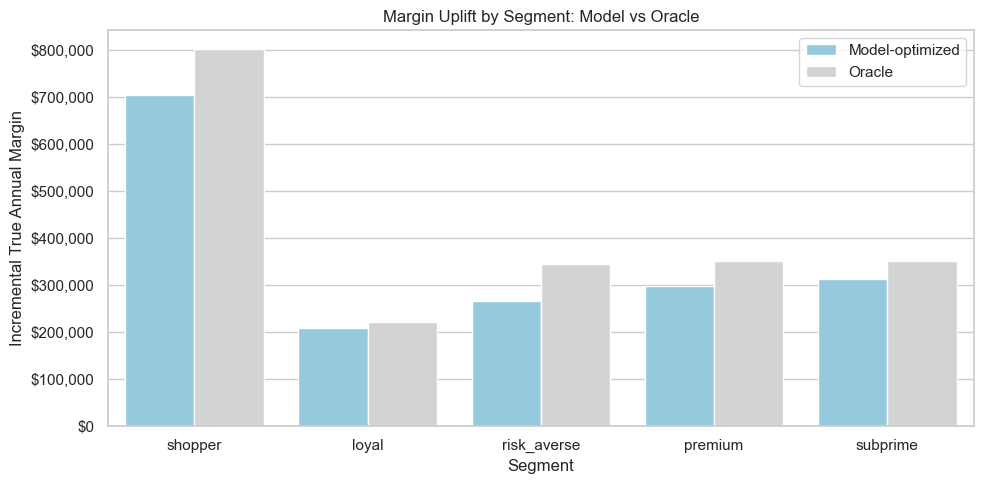

In [48]:
fig, ax = plt.subplots(figsize=(10, 5))

uplift_plot = pd.DataFrame({
    "Model-optimized": segment_summary["true_incremental_margin"],
    "Oracle": segment_summary["true_margin_oracle"] - segment_summary["true_margin_current"],
}).reset_index().melt(id_vars="segment", var_name="strategy", value_name="uplift")

sns.barplot(data=uplift_plot, x="segment", y="uplift", hue="strategy",
            palette={"Model-optimized": "skyblue", "Oracle": "lightgrey"}, ax=ax)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
ax.set_xlabel("Segment")
ax.set_ylabel("Incremental True Annual Margin")
ax.set_title("Margin Uplift by Segment: Model vs Oracle")
ax.legend(title="")
fig.tight_layout()
save_figure("mort_rate_opt_uplift_by_segment.png")
plt.show()

#### Boundary Check

If most customers landed on a search boundary, it would signal that the objective is unbounded within the grid and that the price response is too weak to produce a real optimum. The share of customers at each boundary is reported here. Customers at the loyalty cap are bound by policy rather than by the search range.

In [49]:
boundary_check = pd.DataFrame({
    "at_max_increase (+50 bps)": (df_optimized["change_bps"] == PRICING_RULES["max_up_bps"]),
    "at_loyalty_cap (+15 bps, protected)": df_optimized["loyalty_protected"] & df_optimized["at_upper_limit"],
    "at_max_decrease (-75 bps) or floor": df_optimized["at_lower_limit"],
    "interior solution": ~(df_optimized["at_upper_limit"] | df_optimized["at_lower_limit"]),
}).groupby(df_optimized["segment"]).mean().reindex(SEGMENTS)

boundary_check.loc["portfolio"] = boundary_check.mul(segment_summary["customers"], axis=0).sum() / len(df_optimized)
display(boundary_check.style.format("{:.1%}"))

,at_max_increase (+50 bps),"at_loyalty_cap (+15 bps, protected)",at_max_decrease (-75 bps) or floor,interior solution
segment,,,,
shopper,0.8%,1.1%,8.5%,89.7%
loyal,0.0%,81.3%,0.2%,18.5%
risk_averse,7.7%,3.9%,1.9%,86.5%
premium,21.5%,8.4%,0.7%,69.3%
subprime,0.0%,0.4%,20.4%,79.2%
portfolio,5.0%,18.8%,5.8%,70.5%


#### Mortgage Offer Rate Optimization: Summary and Insights

* **Differentiated pricing replaces a uniform increase.** Price-sensitive shoppers and subprime customers receive discounts that retain enough additional customers to more than offset the lower spread. Premium and risk-averse customers, who are less price sensitive, absorb increases.
* **Margin and retention can improve together.** Because discounts are concentrated where they change behavior most, portfolio acceptance does not have to fall for margin to rise.
* **The model captures most of the achievable value.** The share of oracle uplift is the honest measure of model value. The remaining gap comes from unobservable customer traits and from the model's imperfect estimate of each segment's price slope.
* **Loyalty protection has a measurable cost.** Many loyal customers sit at the +15 bps cap, which means the policy forgoes some short-term margin. That is a deliberate trade-off for relationship value the annual margin objective does not capture.
* **Price response fidelity matters more than AUC.** Random Forest's AUC is within 0.005 of Logistic Regression's, yet because it understates price sensitivity it raises rates where it should discount and captures only about a third of the oracle uplift, versus over 80% for Logistic Regression and XGBoost. A pricing model should be judged on its price response, not just its ranking metrics.

**Limitations**

* The acceptance function is synthetic, so results show the method working on known ground truth rather than measuring real customer behavior.
* The objective uses one year of margin on full principal. A production version would use lifetime value, amortizing balances, and the cost of replacing a lost customer.
* Historical offers here vary randomly. Real pricing data is confounded, because rate desks discount customers they believe are at risk, so a production model would need experimentation or causal adjustment to estimate price sensitivity.

---

## Appendix

*Saving models, data, metrics, and reproducibility info*

In [50]:
# saving trained model pipelines
for name, pipeline in strategy_pipelines.items():
    joblib.dump(pipeline, MODELS_DIR / f"{name.lower().replace(' ', '_')}_pipeline.pkl")

# saving datasets
df_time_series.to_csv(DATA_DIR / "df_time_series.csv", index=False)
df_optimized.to_csv(DATA_DIR / "final_optimized_rates.csv", index=False)

# saving summary metrics
model_metrics.to_csv(METRICS_DIR / "model_metrics.csv")
strategy_comparison.to_csv(METRICS_DIR / "strategy_comparison.csv")
portfolio_summary.to_csv(METRICS_DIR / "portfolio_summary_metrics.csv", index=False)
segment_summary.to_csv(METRICS_DIR / "segment_summary_metrics.csv")

# saving reproducibility info
import sklearn, xgboost, scipy, matplotlib
(REPRO_DIR / "run_info.txt").write_text(
    f"Global SEED used: {SEED}\n"
    f"Pricing rules: {PRICING_RULES}\n"
    f"numpy=={np.__version__}\npandas=={pd.__version__}\nscipy=={scipy.__version__}\n"
    f"matplotlib=={matplotlib.__version__}\nseaborn=={sns.__version__}\n"
    f"scikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}\n"
)

print(f"All project assets saved to {OUTPUTS_DIR.relative_to(PROJECT_ROOT)}")

All project assets saved to outputs
